# Tracks, Tickets and Territories
## A Spatially Heterogeneous Analysis of Train Accessibility, House Prices and Population Characteristics in Greater Melbourne

**GEOM90006 Spatial Data Analytics — Assignment 4 Major Project**

**Group 15** · Xianglong Fu · Balqes Mahdi M Alatawi · Chang Gu

University of Melbourne, Semester 1 2026

---

This notebook investigates the relationships between metro train accessibility, house prices and neighbourhood demographics across Greater Melbourne. We test whether the station-proximity premium is spatially heterogeneous, identify potential transit deserts, and examine spatial clustering of house prices. Three research questions are addressed using Exploratory Spatial Data Analysis (ESDA), point pattern analysis, local indicators of spatial association (LISA), and Geographically Weighted Regression (GWR).

---
# Part 1 — Project Introduction

## Topic and research questions

Train stations, house prices and the people who live nearby form a connected spatial system. Most studies ask whether being close to a train station raises house prices, and report one single average answer for the whole city. But this premium is not the same everywhere — it is strong in some neighbourhoods and weak or even absent in others (Dziauddin, 2019; Dziauddin, Powe & Alvanides, 2015). This project examines how the relationship varies across Greater Melbourne using house sales, train station, and demographic data, plus environmental layers on rainfall and population density.

We address three inter-related questions, each examining a different facet of the same spatial system:

1. How does the relationship between proximity to a metro train station and house price vary spatially across Greater Melbourne, and which neighbourhood characteristics — income, education, family structure — explain this variation?
2. Where does poor train accessibility coincide with markers of socio-economic disadvantage, indicating potential "transit deserts"?
3. Are house prices spatially clustered (and at what scale), and do these clusters align with — or diverge from — the train network?

## Scope and data

**Geographic area:** Greater Melbourne GCCSA (ABS ASGS Edition 3), 577 SAL (Suburb and Locality) polygons.
**Spatial units:** Houses as points; SAL as polygons (analysis unit); rainfall and population as rasters.
**Temporal scope:** House sales 2016–17; Census 2021; PTV GTFS metro train network. Sales pre-date the Metro Tunnel, so the pre-Tunnel City Loop configuration is treated as the explanatory network.
**Working CRS:** GDA2020 / MGA Zone 55 (EPSG:7855, metric).

| Layer | Type | Source |
|------|------|--------|
| Melbourne house sales 2016–17 (n = 13,580) | Point | A2 dataset |
| Greater Melbourne study area | Polygon | A2 dataset (ABS) |
| Census 2021 G02 (income, age, household size) | Polygon (SAL) | A2 dataset (ABS) |
| Metro train stations (n = 226) | Point | PTV GTFS Schedule (2026) |
| Mean annual rainfall (Victoria) | Raster | A3 dataset (Bureau of Meteorology) |
| Mesh Block population (2021) | Polygon → derived raster | ABS Mesh Block Counts (2021) |

## Literature review

House prices can be decomposed into the value of individual attributes, including proximity to transit (Rosen, 1974). In a recent Melbourne study, Zhang and Shukla (2023) find a substantial price premium near the Mernda heavy-rail extension. However, Liang et al. (2025) caution that effects depend on transit mode and service quality, with buses and trams in Melbourne showing very different effects from heavy rail.

A key theme in recent work is that this premium is not uniform across a city — it varies by neighbourhood and can even be negative in some areas. Dziauddin, Powe and Alvanides (2015) and Dziauddin (2019), studying Kuala Lumpur's light rail, show that proximity is valued positively in some housing estates and negligibly or negatively in others, depending on local socio-economic context. Wang et al. (2025) report similar spatial variation in Qingdao using multiscale GWR. A parallel strand of transit equity research (Karner, 2018; Anselin, 1995) reframes the question: rather than asking what the average household gains, it asks where benefits and burdens fall. The gap motivating our project is the absence, in Melbourne work, of a study that combines station proximity, house-price clustering and population disadvantage within a single analysis.

---
# Part 2 — ESDA and Point Pattern Analysis

_This section combines exploratory data analysis with point-pattern techniques (KDE, ANN, K/L functions). It addresses RQ3 by examining whether house sales and train stations cluster spatially before any statistical modelling._

In [40]:
# === Imports ===
# All packages used anywhere in this notebook (Part 2 ESDA, Part 3 point pattern,
# Part 4 LISA, Part 5 GWR).
# Run this cell once; everything below uses these imports.

from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import zipfile, io
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib_scalebar.scalebar import ScaleBar
import contextily as cx

# Stats + spatial
from scipy import stats
from scipy.stats import spearmanr
from scipy.spatial import KDTree
from numpy.polynomial.polynomial import polyfit
from statsmodels.api import OLS, add_constant
from sklearn.preprocessing import StandardScaler
import libpysal
from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local, Moran_BV, Moran_Local_BV
from esda.getisord import G_Local
from splot.esda import plot_moran
import pointpats
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

# Paths + CRS (working / Web Mercator)
REPO = Path.cwd()
ASG  = REPO / "assignment_data"
PROC = REPO / "data" / "processed"
CRS_PROJ = 7855   # GDA2020 / MGA Zone 55 (metric)
CRS_WEB  = 3857   # for OSM/CARTO basemap overlays

print(f"Repo root: {REPO}")
print("✓ imports OK")

Repo root: /Users/fuxianglong/Desktop/GEOM_Team_15_Submission
✓ imports OK


In [41]:
# === Centralised data loading ===
# Every dataset used anywhere in this notebook is loaded here.
# Do NOT re-load these in later cells — just reference the variable names.
# Variables defined here:
#
#   Greater Melbourne boundary
#     gm           — GeoDataFrame in EPSG:7855 (single polygon)
#     gm_web       — same, reprojected to EPSG:3857 for basemap overlays
#
#   SAL polygons (Suburb and Locality, 577 in Greater Melbourne)
#     sal_mel      — clipped to Greater Melbourne, EPSG:7855, with census attrs
#     sal_web      — same, EPSG:3857
#
#   House sales (2016–17, n ≈ 13,580 after dropping invalid rows)
#     sales_gdf    — points, EPSG:7855, already spatially-joined to SAL
#
#   Metro train stations (PTV GTFS, branch 2, n = 226)
#     stations_mel — points, EPSG:7855, clipped to Greater Melbourne
#
#   Feature matrix at SAL level (target + 6 predictors, 577 rows)
#     features     — GeoDataFrame, EPSG:7855
#                    Use features.dropna(subset=required_cols) to get
#                    the 318 complete-case SALs ready for GWR.
#
#   Rainfall raster (Victoria, A3 dataset)
#     rain_path    — Path to the .asc file (use rasterio.open when needed)

# 1. Greater Melbourne boundary
gm = gpd.read_file(ASG / "Greater Melbourne (ABS) study area.shp").to_crs(CRS_PROJ)
gm_web = gm.to_crs(CRS_WEB)
print(f"[1/5] Greater Melbourne boundary loaded ({len(gm)} polygon)")

# 2. SAL polygons + census attributes
sal_all = gpd.read_file(ASG / "Census 2021 table G02 Victoria.gpkg").to_crs(CRS_PROJ)
sal_mel = gpd.clip(sal_all, gm).copy().reset_index(drop=True)
sal_web = sal_mel.to_crs(CRS_WEB)
print(f"[2/5] SAL polygons loaded ({len(sal_mel)} SALs in Greater Melbourne)")

# 3. House sales — load + spatial-join to SAL
sales_raw = pd.read_csv(ASG / "Melbourne house sales.csv")
sales_raw = sales_raw.dropna(subset=["Latitude", "Longitude", "Price"])
sales_gdf = gpd.GeoDataFrame(
    sales_raw,
    geometry=gpd.points_from_xy(sales_raw["Longitude"], sales_raw["Latitude"]),
    crs="EPSG:4326",
).to_crs(CRS_PROJ)
sales_gdf = gpd.sjoin(sales_gdf, sal_mel, how="left",
                      predicate="within").dropna(subset=["SAL_NAME_2021"])
if "index_right" in sales_gdf.columns:
    sales_gdf = sales_gdf.drop(columns="index_right")
print(f"[3/5] House sales loaded ({len(sales_gdf):,} sales, "
      f"{sales_gdf['SAL_NAME_2021'].nunique()} unique SALs)")

# 4. Metro train stations from processed GTFS
with zipfile.ZipFile(PROC / "gtfs_metro_train.zip") as outer:
    inner = next(n for n in outer.namelist()
                 if n.startswith("2/") and n.endswith(".zip"))
    with outer.open(inner) as f:
        with zipfile.ZipFile(io.BytesIO(f.read())) as z:
            stops_raw = pd.read_csv(z.open("stops.txt"))
stations = stops_raw[stops_raw["location_type"] == 1].copy()
stations_gdf = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["stop_lon"], stations["stop_lat"]),
    crs="EPSG:4326",
).to_crs(CRS_PROJ)
stations_mel = gpd.sjoin(stations_gdf, gm, predicate="within",
                          how="inner").reset_index(drop=True)
if "index_right" in stations_mel.columns:
    stations_mel = stations_mel.drop(columns="index_right")
print(f"[4/5] Metro train stations loaded ({len(stations_mel)} stations)")

# 5. Master feature matrix (built in 02_feature_engineering.ipynb)
features = gpd.read_file(PROC / "sal_features.gpkg")
rain_path = ASG / "Victoria rainfall grid.asc"
print(f"[5/5] Feature matrix loaded ({len(features)} SAL rows × "
      f"{features.shape[1]} cols)")

print("\n✓ all data ready. Variables available downstream:")
print("    gm, gm_web, sal_mel, sal_web, sales_gdf, stations_mel,")
print("    features, rain_path")

[1/5] Greater Melbourne boundary loaded (1 polygon)
[2/5] SAL polygons loaded (577 SALs in Greater Melbourne)
[3/5] House sales loaded (13,580 sales, 318 unique SALs)
[4/5] Metro train stations loaded (226 stations)
[5/5] Feature matrix loaded (577 SAL rows × 19 cols)

✓ all data ready. Variables available downstream:
    gm, gm_web, sal_mel, sal_web, sales_gdf, stations_mel,
    features, rain_path


In [42]:
# === Unified "pretty map" helper ===
# Adds OSM basemap + scale bar + north arrow + source caption,
# matching the BOLTSS-style maps used across this project.

BASEMAP = cx.providers.CartoDB.Positron

SOURCE_TEXT = (
    "Sources: ABS ASGS Edition 3 (2021); PTV GTFS (2026);\n"
    "A2 & A3 datasets (GEOM90006). Coordinate system: Web Mercator (EPSG:3857)."
)


def pretty_map(ax, title, gm_web=None, show_source=True):
    """Apply the standard cartographic frame to ax.

    Call this AFTER plotting all data layers (so legend/scale sit on top).
    """
    if gm_web is not None:
        gm_web.plot(ax=ax, facecolor="none", edgecolor="black",
                    linewidth=1.0, zorder=20)

    cx.add_basemap(ax, source=BASEMAP, zoom="auto", attribution_size=6)
    ax.set_title(title, fontsize=12, pad=10, fontweight="bold")
    ax.set_axis_off()

    # North arrow
    x_n, y_n = 0.95, 0.965
    ax.annotate("N", xy=(x_n, y_n), xycoords="axes fraction",
                fontsize=13, fontweight="bold", ha="center", va="center")
    ax.annotate("\u25b2", xy=(x_n, y_n - 0.035), xycoords="axes fraction",
                fontsize=14, ha="center", va="center")

    # Scale bar
    scalebar = ScaleBar(
        dx=1, units="m", location="lower left",
        length_fraction=0.18, box_alpha=0.85,
        font_properties={"size": 8},
        scale_loc="bottom", pad=0.5, border_pad=1.5,
    )
    ax.add_artist(scalebar)

    # Source caption
    if show_source:
        ax.text(0.5, 0.01, SOURCE_TEXT, transform=ax.transAxes,
                fontsize=6.5, color="#444444", va="bottom", ha="center",
                bbox=dict(facecolor="white", alpha=0.85,
                          edgecolor="none", pad=2))


print("\u2713 pretty_map helper ready")

✓ pretty_map helper ready


---
## 2.1 Aggregate house sales to SAL level

Each of the 13,580 house sales is a point event. We spatial-join each sale to its containing SAL polygon, then compute **per-SAL summary statistics**:
- `n_sales` — number of sales in the SAL (quality indicator)
- `mean_price` — mean sale price
- `median_price` — median sale price (robust to outliers)
- `std_price` — standard deviation of sale prices within the SAL
- `min_price` / `max_price` — price range

The median is preferred as the target variable for GWR because it is robust to outlier sales within a suburb.

SALs with at least one sale: 318
SALs with NO sales: 259

sales-per-SAL distribution:
count    318.000000
mean      42.704403
std       55.052089
min        1.000000
25%        6.000000
50%       20.000000
75%       59.000000
max      366.000000
Name: n_sales, dtype: float64


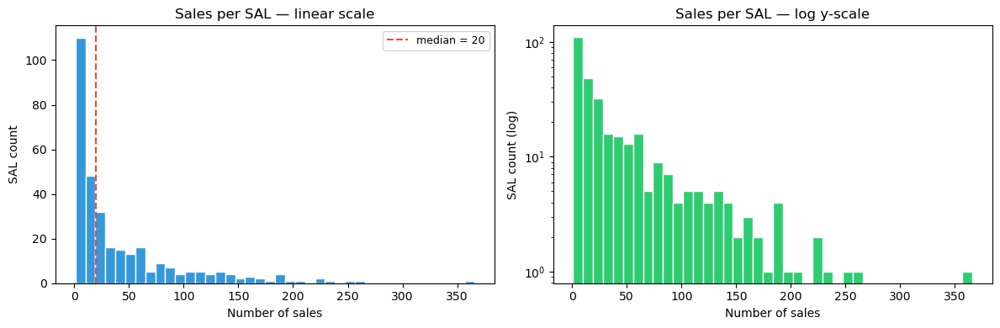

In [43]:
# === Number of sales per SAL (coverage / quality indicator) ===

sales_per_sal = (
    sales_gdf.groupby("SAL_CODE_2021")
    .size()
    .rename("n_sales")
    .reset_index()
)
print(f"SALs with at least one sale: {len(sales_per_sal)}")
print(f"SALs with NO sales: {len(sal_mel) - len(sales_per_sal)}")
print(f"\nsales-per-SAL distribution:")
print(sales_per_sal["n_sales"].describe())

# Histogram of sales per SAL
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sales_per_sal["n_sales"], bins=40, color="#3498db", edgecolor="white")
axes[0].axvline(sales_per_sal["n_sales"].median(), color="#e74c3c",
                linestyle="--", linewidth=1.5,
                label=f"median = {sales_per_sal['n_sales'].median():.0f}")
axes[0].set_xlabel("Number of sales")
axes[0].set_ylabel("SAL count")
axes[0].set_title("Sales per SAL — linear scale")
axes[0].legend(fontsize=9)

axes[1].hist(sales_per_sal["n_sales"], bins=40, color="#2ecc71", edgecolor="white")
axes[1].set_xlabel("Number of sales")
axes[1].set_ylabel("SAL count (log)")
axes[1].set_yscale("log")
axes[1].set_title("Sales per SAL — log y-scale")

plt.tight_layout()
plt.show()
# Release memory for Jupyter inline backend
plt.close("all")


In [44]:
# === Mean + median sale price per SAL ===

price_per_sal = (
    sales_gdf.groupby("SAL_CODE_2021")
    .agg(
        mean_price=("Price", "mean"),
        median_price=("Price", "median"),
        std_price=("Price", "std"),
        min_price=("Price", "min"),
        max_price=("Price", "max"),
        n_sales=("Price", "size"),
    )
    .reset_index()
)

# Log-transform the median (target variable for GWR — handles right skew)
price_per_sal["log_mean_price"] = np.log(price_per_sal["mean_price"])
price_per_sal["log_median_price"] = np.log(price_per_sal["median_price"])

print("Per-SAL price summary statistics:")
print(price_per_sal[["mean_price", "median_price", "std_price",
                     "log_mean_price", "log_median_price", "n_sales"]].describe())

# Mean vs median comparison — how much skew within each SAL?
price_per_sal["mean_median_ratio"] = (
    price_per_sal["mean_price"] / price_per_sal["median_price"]
)
print(f"\nMean/median ratio (1.0 = symmetric within-SAL distribution):")
price_per_sal["mean_median_ratio"].describe()

Per-SAL price summary statistics:
         mean_price  median_price     std_price  log_mean_price  \
count  3.180000e+02  3.180000e+02  2.950000e+02      318.000000   
mean   9.269148e+05  8.949743e+05  3.282992e+05       13.670244   
std    3.572311e+05  3.433525e+05  2.736562e+05        0.371839   
min    2.850000e+05  2.850000e+05  7.071068e+02       12.560244   
25%    6.536723e+05  6.400000e+05  1.310560e+05       13.390361   
50%    8.528864e+05  8.172500e+05  2.390801e+05       13.656375   
75%    1.108916e+06  1.075938e+06  4.624610e+05       13.918893   
max    2.185000e+06  2.185000e+06  1.512455e+06       14.597126   

       log_median_price     n_sales  
count        318.000000  318.000000  
mean          13.636889   42.704403  
std            0.365467   55.052089  
min           12.560244    1.000000  
25%           13.369223    6.000000  
50%           13.613700   20.000000  
75%           13.888703   59.000000  
max           14.597126  366.000000  

Mean/median ratio (

count    318.000000
mean       1.038017
std        0.100504
min        0.815148
25%        0.995899
50%        1.008720
75%        1.045273
max        1.637689
Name: mean_median_ratio, dtype: float64

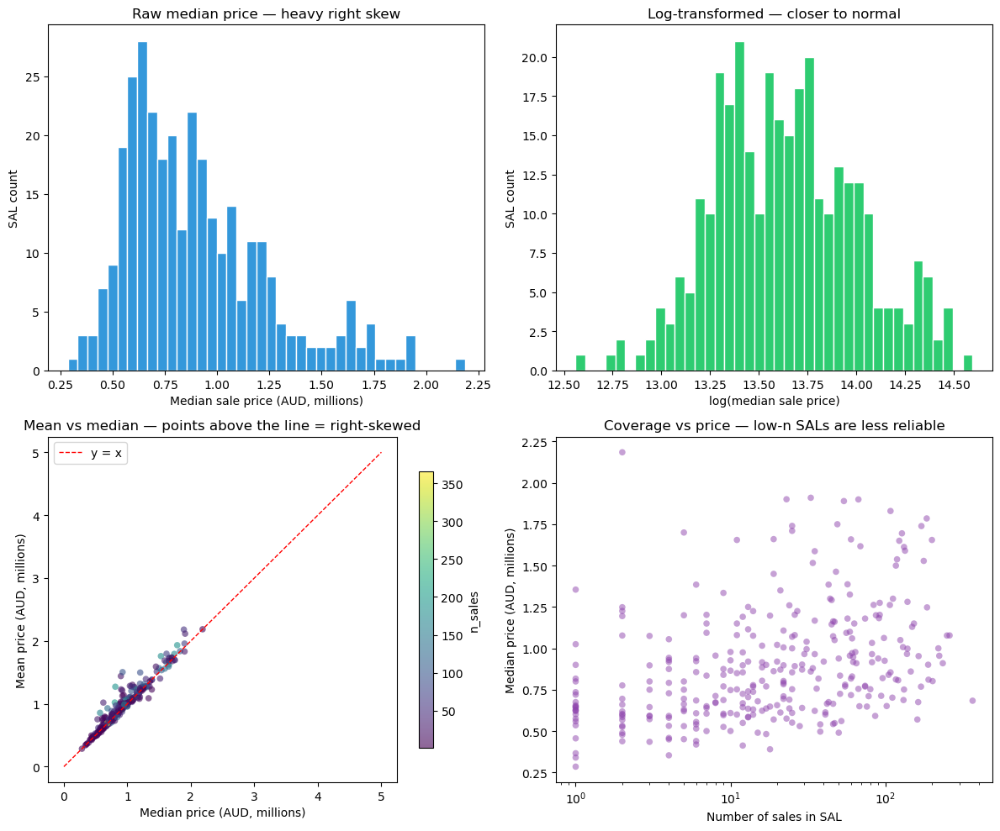

In [45]:
# === Visualise raw vs log-transformed median price ===

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Raw median price
axes[0, 0].hist(price_per_sal["median_price"] / 1e6, bins=40,
                color="#3498db", edgecolor="white")
axes[0, 0].set_xlabel("Median sale price (AUD, millions)")
axes[0, 0].set_ylabel("SAL count")
axes[0, 0].set_title("Raw median price — heavy right skew")

# Log median price
axes[0, 1].hist(price_per_sal["log_median_price"], bins=40,
                color="#2ecc71", edgecolor="white")
axes[0, 1].set_xlabel("log(median sale price)")
axes[0, 1].set_ylabel("SAL count")
axes[0, 1].set_title("Log-transformed — closer to normal")

# Mean vs median scatter
axes[1, 0].scatter(price_per_sal["median_price"] / 1e6,
                   price_per_sal["mean_price"] / 1e6,
                   c=price_per_sal["n_sales"], cmap="viridis",
                   alpha=0.6, edgecolor="none", s=30)
axes[1, 0].plot([0, 5], [0, 5], "r--", linewidth=1, label="y = x")
axes[1, 0].set_xlabel("Median price (AUD, millions)")
axes[1, 0].set_ylabel("Mean price (AUD, millions)")
axes[1, 0].set_title("Mean vs median — points above the line = right-skewed")
axes[1, 0].legend()
cbar = plt.colorbar(axes[1, 0].collections[0], ax=axes[1, 0], shrink=0.8)
cbar.set_label("n_sales")

# Price vs n_sales — does coverage affect reliability?
axes[1, 1].scatter(price_per_sal["n_sales"], price_per_sal["median_price"] / 1e6,
                   alpha=0.5, edgecolor="none", s=30, color="#8e44ad")
axes[1, 1].set_xlabel("Number of sales in SAL")
axes[1, 1].set_ylabel("Median price (AUD, millions)")
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Coverage vs price — low-n SALs are less reliable")

plt.tight_layout()
plt.show()
# Release memory for Jupyter inline backend
plt.close("all")


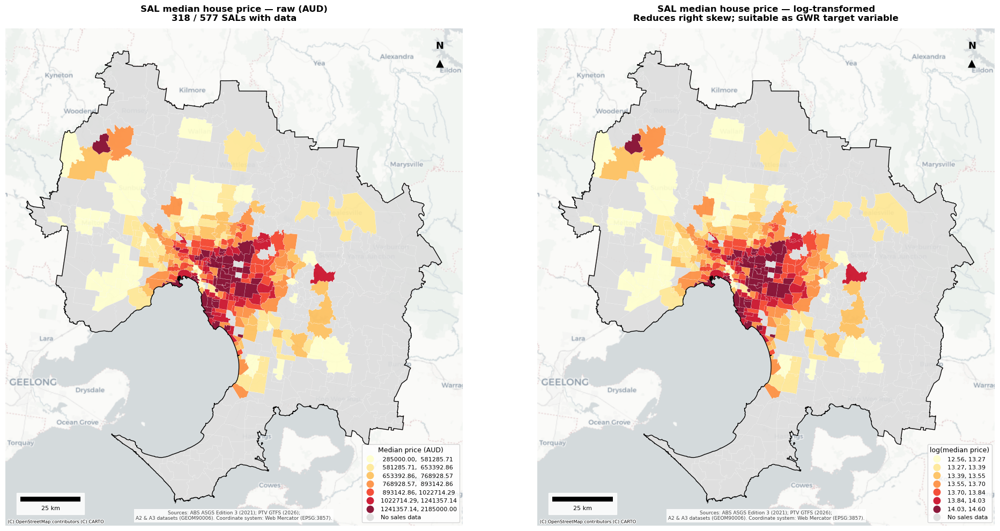

✓ Step 1 complete — price aggregation at SAL level


In [46]:
# === Map: SAL choropleth of median house price ===

# Merge price stats onto SAL polygons
sal_price = sal_mel.merge(
    price_per_sal[["SAL_CODE_2021", "median_price", "log_median_price", "n_sales"]],
    on="SAL_CODE_2021", how="left",
)
sal_price_web = sal_price.to_crs(CRS_WEB)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Raw median price
sal_price_web.plot(
    ax=axes[0], column="median_price", cmap="YlOrRd",
    scheme="quantiles", k=7,
    edgecolor="white", linewidth=0.15, alpha=0.9,
    legend=True,
    legend_kwds={"loc": "lower right",
                 "title": "Median price (AUD)",
                 "fontsize": 8, "title_fontsize": 9},
    missing_kwds={"color": "#dddddd", "label": "No sales data"},
    zorder=5,
)
pretty_map(axes[0],
           f"SAL median house price — raw (AUD)\n"
           f"{sal_price['median_price'].notna().sum()} / {len(sal_price)} SALs with data",
           gm_web=gm_web)

# Log median price
sal_price_web.plot(
    ax=axes[1], column="log_median_price", cmap="YlOrRd",
    scheme="quantiles", k=7,
    edgecolor="white", linewidth=0.15, alpha=0.9,
    legend=True,
    legend_kwds={"loc": "lower right",
                 "title": "log(median price)",
                 "fontsize": 8, "title_fontsize": 9},
    missing_kwds={"color": "#dddddd", "label": "No sales data"},
    zorder=5,
)
pretty_map(axes[1],
           f"SAL median house price — log-transformed\n"
           f"Reduces right skew; suitable as GWR target variable",
           gm_web=gm_web)

plt.tight_layout()
plt.show()

print("\u2713 Step 1 complete — price aggregation at SAL level")
# Release memory for Jupyter inline backend
plt.close("all")


---
## 2.2 Euclidean distance from each house to its nearest train station

For each of the 13,580 house sales, compute the straight-line (Euclidean) distance to the nearest metro train station. This uses **`gpd.sjoin_nearest`**, which internally builds an **STRtree** spatial index — an R-tree variant that achieves O(n log n) nearest-neighbour search instead of the naive O(n × m) pairwise comparison.

**Why STRtree?** The naive approach (computing distances from 13,580 houses to 226 stations = 3 million distance calculations) is slow. Sorting-based R-trees reduce this to ~13,580 × log(226) ≈ 100k indexed lookups — a ~30× speedup.

After computing house-level distances, we aggregate to SAL level by taking the **median distance** per suburb — robust to outlier houses within a SAL.

In [47]:
# === House-level distance to nearest train station ===
# gpd.sjoin_nearest uses STRtree internally — spatial-index-backed nearest
# search. The distance_col parameter gives us the Euclidean distance in
# metres (because both layers are in EPSG:7855, a metric CRS).

# Prepare station GeoDataFrame with just geometry
stations_xy = stations_mel[["geometry"]].copy().reset_index(drop=True)

# For each sale, find the single nearest station + the distance in metres
sales_with_dist = gpd.sjoin_nearest(
    sales_gdf,
    stations_xy,
    how="left",
    distance_col="dist_station_m",
    max_distance=None,       # no cap — every house gets a match
    exclusive=False,          # keep all sales (no dedup)
)

print(f"sales with distance computed: {len(sales_with_dist):,}")
print(f"\nHouse-level distance to nearest station (metres):")
print(sales_with_dist["dist_station_m"].describe())

# Quick sanity: distances should be non-negative and in a reasonable range
assert (sales_with_dist["dist_station_m"] >= 0).all(), "Negative distances found!"
print(f"\n  min distance: {sales_with_dist['dist_station_m'].min():.0f} m")
print(f"  max distance: {sales_with_dist['dist_station_m'].max():.0f} m "
      f"({sales_with_dist['dist_station_m'].max()/1000:.1f} km)")

sales with distance computed: 13,580

House-level distance to nearest station (metres):
count    13580.000000
mean      1404.161165
std       1432.298637
min         22.853437
25%        593.631599
50%       1000.982440
75%       1735.290551
max      25938.995222
Name: dist_station_m, dtype: float64

  min distance: 23 m
  max distance: 25939 m (25.9 km)


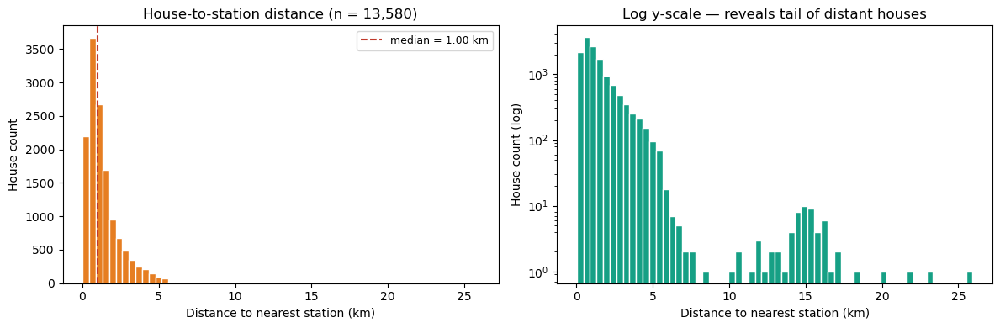

In [48]:
# === Visualise house-level distance distribution ===

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Linear scale
axes[0].hist(sales_with_dist["dist_station_m"] / 1000, bins=60,
             color="#e67e22", edgecolor="white")
axes[0].axvline(sales_with_dist["dist_station_m"].median() / 1000,
                color="#c0392b", linestyle="--", linewidth=1.5,
                label=f"median = {sales_with_dist['dist_station_m'].median()/1000:.2f} km")
axes[0].set_xlabel("Distance to nearest station (km)")
axes[0].set_ylabel("House count")
axes[0].set_title(f"House-to-station distance (n = {len(sales_with_dist):,})")
axes[0].legend(fontsize=9)

# Log scale
axes[1].hist(sales_with_dist["dist_station_m"] / 1000, bins=60,
             color="#16a085", edgecolor="white")
axes[1].set_xlabel("Distance to nearest station (km)")
axes[1].set_ylabel("House count (log)")
axes[1].set_yscale("log")
axes[1].set_title("Log y-scale — reveals tail of distant houses")

plt.tight_layout()
plt.show()
# Release memory for Jupyter inline backend
plt.close("all")


In [49]:
# === Aggregate house-level distance to SAL level ===
# For each SAL, take the median distance among its houses, then log-transform.
# Median is used (not mean) to be robust against outlier houses at the SAL edge.

dist_per_sal = (
    sales_with_dist.groupby("SAL_CODE_2021")
    .agg(
        mean_dist_station_m=("dist_station_m", "mean"),
        median_dist_station_m=("dist_station_m", "median"),
        min_dist_station_m=("dist_station_m", "min"),
        max_dist_station_m=("dist_station_m", "max"),
    )
    .reset_index()
)

# +1 avoids log(0) for houses directly at a station
dist_per_sal["log_dist_station_m"] = np.log(
    dist_per_sal["median_dist_station_m"] + 1
)

print(f"SALs with distance data: {len(dist_per_sal)}")
print(f"\nSAL-level distance summary:")
dist_per_sal[["mean_dist_station_m", "median_dist_station_m",
              "min_dist_station_m", "max_dist_station_m",
              "log_dist_station_m"]].describe()

SALs with distance data: 318

SAL-level distance summary:


,mean_dist_station_m,median_dist_station_m,min_dist_station_m,max_dist_station_m,log_dist_station_m
count,318.000000,318.000000,318.000000,318.000000,318.000000
mean,2582.623746,2575.821444,1930.743331,3272.380952,7.372269
std,3614.768474,3620.010661,3664.547168,3594.193139,0.890978
min,275.117362,275.117362,22.853437,442.238445,5.620826
25%,825.639487,822.675717,219.322383,1478.623091,6.713775
50%,1391.557805,1401.624555,693.559290,2167.055092,7.245984
75%,2602.421195,2604.040423,1875.120772,3432.331791,7.865165
max,25938.995222,25938.995222,25938.995222,25938.995222,10.163541


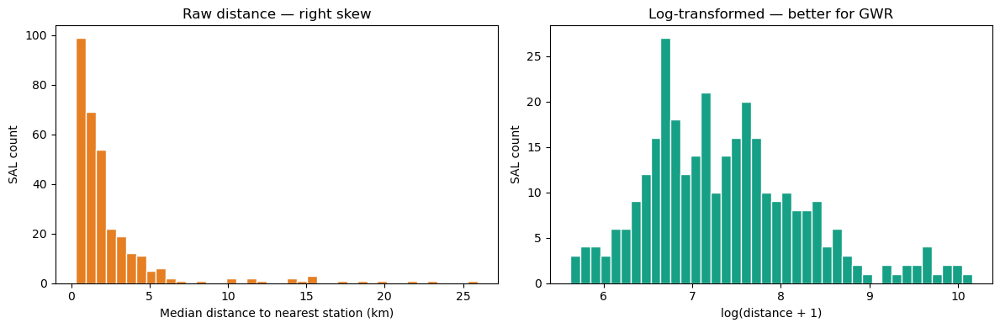

In [50]:
# === SAL-level distance: raw vs log ===

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(dist_per_sal["median_dist_station_m"] / 1000, bins=40,
             color="#e67e22", edgecolor="white")
axes[0].set_xlabel("Median distance to nearest station (km)")
axes[0].set_ylabel("SAL count")
axes[0].set_title("Raw distance — right skew")

axes[1].hist(dist_per_sal["log_dist_station_m"], bins=40,
             color="#16a085", edgecolor="white")
axes[1].set_xlabel("log(distance + 1)")
axes[1].set_ylabel("SAL count")
axes[1].set_title("Log-transformed — better for GWR")

plt.tight_layout()
plt.show()
# Release memory for Jupyter inline backend
plt.close("all")


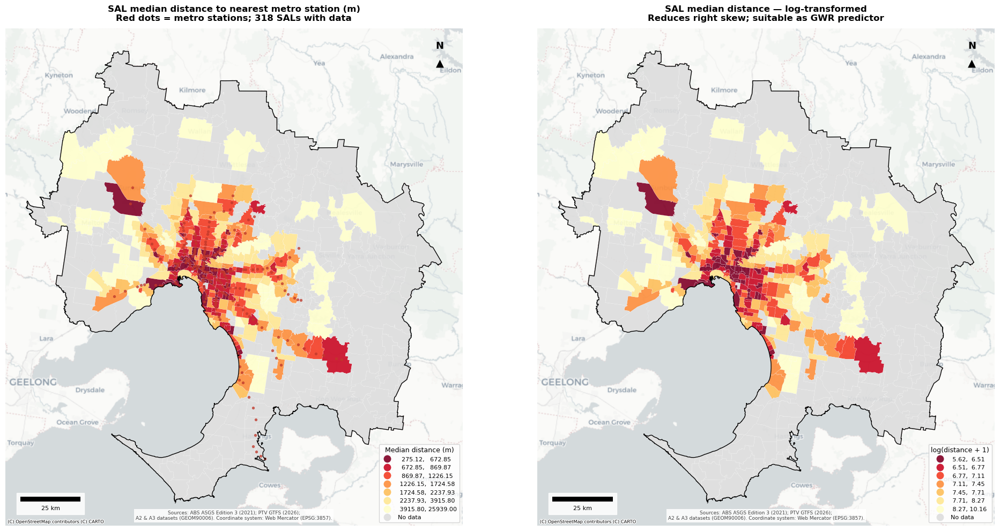

In [51]:
# === Map: SAL choropleth of median distance to nearest station ===

sal_dist = sal_mel.merge(
    dist_per_sal[["SAL_CODE_2021", "median_dist_station_m", "log_dist_station_m"]],
    on="SAL_CODE_2021", how="left",
)
sal_dist_web = sal_dist.to_crs(CRS_WEB)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Raw distance
sal_dist_web.plot(
    ax=axes[0], column="median_dist_station_m", cmap="YlOrRd_r",
    scheme="quantiles", k=7,
    edgecolor="white", linewidth=0.15, alpha=0.9,
    legend=True,
    legend_kwds={"loc": "lower right",
                 "title": "Median distance (m)",
                 "fontsize": 8, "title_fontsize": 9},
    missing_kwds={"color": "#dddddd", "label": "No data"},
    zorder=5,
)
# Overlay stations
stations_mel.to_crs(CRS_WEB).plot(
    ax=axes[0], color="#c0392b", markersize=8, alpha=0.7, zorder=6,
)
pretty_map(axes[0],
           f"SAL median distance to nearest metro station (m)\n"
           f"Red dots = metro stations; "
           f"{sal_dist['median_dist_station_m'].notna().sum()} SALs with data",
           gm_web=gm_web)

# Log distance
sal_dist_web.plot(
    ax=axes[1], column="log_dist_station_m", cmap="YlOrRd_r",
    scheme="quantiles", k=7,
    edgecolor="white", linewidth=0.15, alpha=0.9,
    legend=True,
    legend_kwds={"loc": "lower right",
                 "title": "log(distance + 1)",
                 "fontsize": 8, "title_fontsize": 9},
    missing_kwds={"color": "#dddddd", "label": "No data"},
    zorder=5,
)
pretty_map(axes[1],
           f"SAL median distance — log-transformed\n"
           f"Reduces right skew; suitable as GWR predictor",
           gm_web=gm_web)

plt.tight_layout()
plt.show()

plt.close("all")


---
## 2.3 Joint view: price vs distance

Before building the full GWR design matrix, a quick bivariate check: is there a relationship between proximity to a station and house prices at the SAL level? This previews RQ1.

SALs with both price and distance data: 318


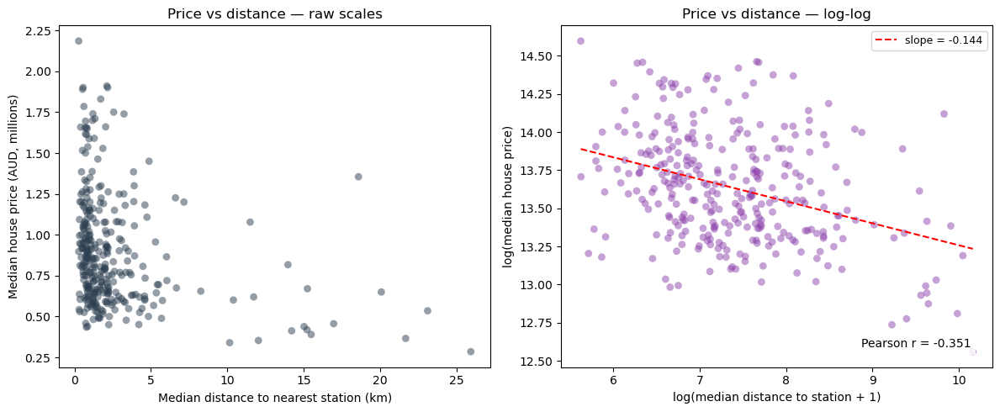


Pearson r (log price vs log distance): -0.351
Negative = houses further from stations tend to be cheaper (as expected).


In [52]:
# === Merge price + distance at SAL level for bivariate exploration ===

sal_bivariate = (
    sal_mel[["SAL_CODE_2021", "SAL_NAME_2021", "geometry"]]
    .merge(price_per_sal[["SAL_CODE_2021", "median_price", "log_median_price"]],
           on="SAL_CODE_2021", how="left")
    .merge(dist_per_sal[["SAL_CODE_2021", "median_dist_station_m", "log_dist_station_m"]],
           on="SAL_CODE_2021", how="left")
    .dropna(subset=["median_price", "median_dist_station_m"])
)
print(f"SALs with both price and distance data: {len(sal_bivariate)}")

# Scatter: log price vs log distance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw scales
axes[0].scatter(sal_bivariate["median_dist_station_m"] / 1000,
                sal_bivariate["median_price"] / 1e6,
                alpha=0.5, edgecolor="none", s=40, color="#2c3e50")
axes[0].set_xlabel("Median distance to nearest station (km)")
axes[0].set_ylabel("Median house price (AUD, millions)")
axes[0].set_title("Price vs distance — raw scales")

# Log-log — the relationship should be clearer
axes[1].scatter(sal_bivariate["log_dist_station_m"],
                sal_bivariate["log_median_price"],
                alpha=0.5, edgecolor="none", s=40, color="#8e44ad")
axes[1].set_xlabel("log(median distance to station + 1)")
axes[1].set_ylabel("log(median house price)")
axes[1].set_title("Price vs distance — log-log")

# Add a lowess or simple linear fit line
x_fit = sal_bivariate["log_dist_station_m"].values
y_fit = sal_bivariate["log_median_price"].values
coefs = polyfit(x_fit, y_fit, 1)
x_line = np.linspace(x_fit.min(), x_fit.max(), 100)
axes[1].plot(x_line, coefs[0] + coefs[1] * x_line,
             "r--", linewidth=1.5, label=f"slope = {coefs[1]:.3f}")
axes[1].legend(fontsize=9)

# Pearson correlation
r = sal_bivariate[["log_median_price", "log_dist_station_m"]].corr().iloc[0, 1]
axes[1].text(0.95, 0.05, f"Pearson r = {r:.3f}", transform=axes[1].transAxes,
             fontsize=10, ha="right", va="bottom",
             bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))

plt.tight_layout()
plt.show()

print(f"\nPearson r (log price vs log distance): {r:.3f}")
print("Negative = houses further from stations tend to be cheaper (as expected).")
# Release memory for Jupyter inline backend
plt.close("all")


---
## 2.4 Univariate: sale price distribution

Before modelling relationships, inspect the target variable itself — at both the individual house level (13,580 sales) and the aggregated SAL level (318 suburbs). A log transformation is essential: house prices are almost always log-normally distributed, and the GWR model assumes (approximately) normal errors.

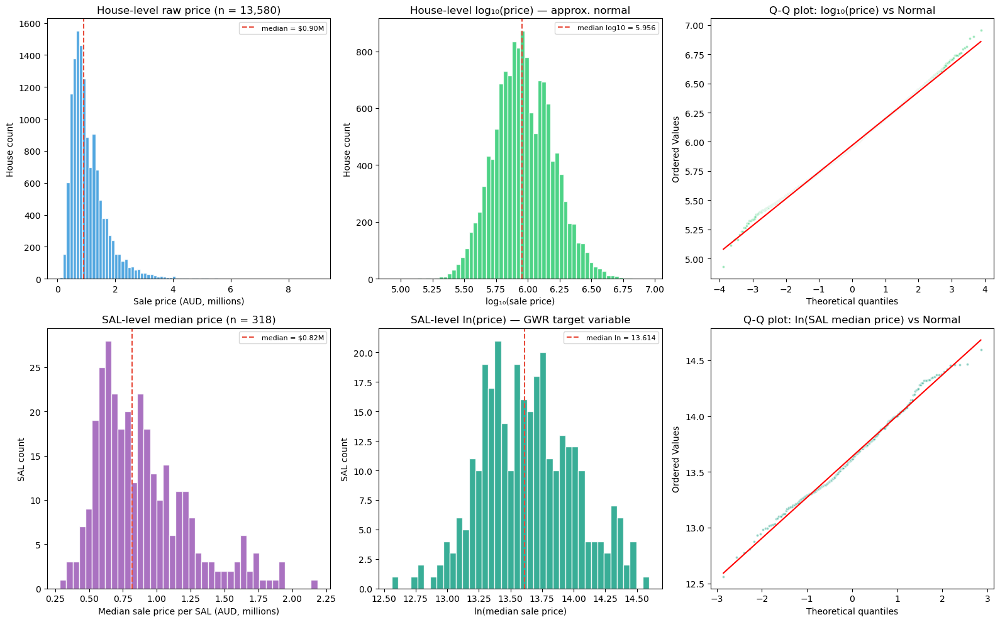

UNIVARIATE SUMMARY — Sale Price

  House-level (n = 13,580):
    Mean  = $1,075,684
    Median = $903,000
    Std   = $639,311
    Min   = $85,000
    Max   = $9,000,000
    Skewness = 2.24
    Kurtosis = 9.87

  SAL-level median price (n = 318):
    Mean of medians  = $894,974
    Median of medians = $817,250
    Std of medians   = $343,353
    Skewness (raw)   = 1.06
    Skewness (log)   = 0.17

  Shapiro-Wilk test for normality of ln(median price):
    W = 0.9920,  p = 0.0821
    Not significantly different from normal (p > 0.05)


In [53]:
# === Univariate: house-level sale price (log scale) ===
# The raw price distribution is heavily right-skewed (a few multi-million
# sales pull the tail). Log-transform reveals the underlying log-normal
# shape — the theoretical basis for using log(price) as the GWR target.

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# --- Row 1: House-level prices ---

# 1a. Raw house prices
axes[0, 0].hist(sales_gdf["Price"] / 1e6, bins=80,
                color="#3498db", edgecolor="white", alpha=0.85)
axes[0, 0].axvline(sales_gdf["Price"].median() / 1e6,
                   color="#e74c3c", linestyle="--", linewidth=1.5,
                   label=f"median = ${sales_gdf['Price'].median()/1e6:.2f}M")
axes[0, 0].set_xlabel("Sale price (AUD, millions)")
axes[0, 0].set_ylabel("House count")
axes[0, 0].set_title(f"House-level raw price (n = {len(sales_gdf):,})")
axes[0, 0].legend(fontsize=8)

# 1b. Log10 house prices — log10 is more intuitive for summary stats
log10_price = np.log10(sales_gdf["Price"])
axes[0, 1].hist(log10_price, bins=60,
                color="#2ecc71", edgecolor="white", alpha=0.85)
axes[0, 1].axvline(log10_price.median(),
                   color="#e74c3c", linestyle="--", linewidth=1.5,
                   label=f"median log10 = {log10_price.median():.3f}")
axes[0, 1].set_xlabel("log₁₀(sale price)")
axes[0, 1].set_ylabel("House count")
axes[0, 1].set_title("House-level log₁₀(price) — approx. normal")
axes[0, 1].legend(fontsize=8)

# 1c. Q-Q plot (log price vs theoretical normal)
stats.probplot(log10_price, dist="norm", plot=axes[0, 2])
axes[0, 2].get_lines()[0].set_markerfacecolor("#2ecc71")
axes[0, 2].get_lines()[0].set_markeredgecolor("white")
axes[0, 2].get_lines()[0].set_markersize(3)
axes[0, 2].get_lines()[0].set_alpha(0.5)
axes[0, 2].set_title("Q-Q plot: log₁₀(price) vs Normal")

# --- Row 2: SAL-level median price ---

# 2a. SAL median price
axes[1, 0].hist(price_per_sal["median_price"] / 1e6, bins=40,
                color="#9b59b6", edgecolor="white", alpha=0.85)
axes[1, 0].axvline(price_per_sal["median_price"].median() / 1e6,
                   color="#e74c3c", linestyle="--", linewidth=1.5,
                   label=f"median = ${price_per_sal['median_price'].median()/1e6:.2f}M")
axes[1, 0].set_xlabel("Median sale price per SAL (AUD, millions)")
axes[1, 0].set_ylabel("SAL count")
axes[1, 0].set_title(f"SAL-level median price (n = {len(price_per_sal)})")
axes[1, 0].legend(fontsize=8)

# 2b. SAL log median price
axes[1, 1].hist(price_per_sal["log_median_price"], bins=40,
                color="#16a085", edgecolor="white", alpha=0.85)
axes[1, 1].axvline(price_per_sal["log_median_price"].median(),
                   color="#e74c3c", linestyle="--", linewidth=1.5,
                   label=f"median ln = {price_per_sal['log_median_price'].median():.3f}")
axes[1, 1].set_xlabel("ln(median sale price)")
axes[1, 1].set_ylabel("SAL count")
axes[1, 1].set_title("SAL-level ln(price) — GWR target variable")
axes[1, 1].legend(fontsize=8)

# 2c. Q-Q plot (SAL log median price vs normal)
stats.probplot(price_per_sal["log_median_price"], dist="norm", plot=axes[1, 2])
axes[1, 2].get_lines()[0].set_markerfacecolor("#16a085")
axes[1, 2].get_lines()[0].set_markeredgecolor("white")
axes[1, 2].get_lines()[0].set_markersize(3)
axes[1, 2].get_lines()[0].set_alpha(0.5)
axes[1, 2].set_title("Q-Q plot: ln(SAL median price) vs Normal")

plt.tight_layout()
plt.show()

# --- Summary statistics table ---
print("=" * 65)
print("UNIVARIATE SUMMARY — Sale Price")
print("=" * 65)
print(f"\n  House-level (n = {len(sales_gdf):,}):")
print(f"    Mean  = ${sales_gdf['Price'].mean():,.0f}")
print(f"    Median = ${sales_gdf['Price'].median():,.0f}")
print(f"    Std   = ${sales_gdf['Price'].std():,.0f}")
print(f"    Min   = ${sales_gdf['Price'].min():,.0f}")
print(f"    Max   = ${sales_gdf['Price'].max():,.0f}")
print(f"    Skewness = {sales_gdf['Price'].skew():.2f}")
print(f"    Kurtosis = {sales_gdf['Price'].kurtosis():.2f}")

print(f"\n  SAL-level median price (n = {len(price_per_sal)}):")
print(f"    Mean of medians  = ${price_per_sal['median_price'].mean():,.0f}")
print(f"    Median of medians = ${price_per_sal['median_price'].median():,.0f}")
print(f"    Std of medians   = ${price_per_sal['median_price'].std():,.0f}")
print(f"    Skewness (raw)   = {price_per_sal['median_price'].skew():.2f}")
print(f"    Skewness (log)   = {price_per_sal['log_median_price'].skew():.2f}")

# Shapiro-Wilk normality test on log price
sw_stat, sw_p = stats.shapiro(price_per_sal["log_median_price"])
print(f"\n  Shapiro-Wilk test for normality of ln(median price):")
print(f"    W = {sw_stat:.4f},  p = {sw_p:.4f}")
print(f"    {'Not significantly different from normal (p > 0.05)' if sw_p > 0.05 else 'Significant deviation from normality (common with large n)'}")

plt.close("all")


---
## 2.5 Bivariate: price vs census demographics

Scatterplots of SAL-level log median price against three key Census G02 predictors: **median weekly personal income**, **median age**, and **average household size**. Each panel reports the **Pearson r** correlation and a linear fit line. These relationships preview the global OLS coefficients from the GWR notebook.


SALs with complete price + demographics: 318


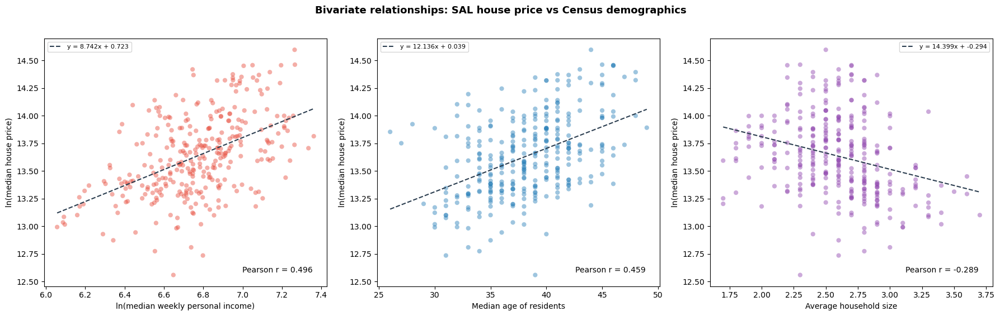


Pearson correlation with ln(median house price):
  ln(median weekly personal income)              r = +0.496
  Median age of residents                        r = +0.459
  Average household size                         r = -0.289


In [54]:
# === Bivariate: merge price with census demographics at SAL level ===

# Extract census variables from sal_mel; handle non-residential SALs
# (income=0 → NaN, consistently with 02_feature_engineering.ipynb)
demog = sal_mel[[
    "SAL_CODE_2021",
    "Median_tot_prsnl_inc_weekly",
    "Median_age_persons",
    "Average_household_size",
]].copy()

# Flag and NaN-out non-residential SALs (parks, industrial, water)
for col in ["Median_tot_prsnl_inc_weekly", "Median_age_persons",
            "Average_household_size"]:
    demog[col] = demog[col].replace(0, np.nan)

demog = demog.rename(columns={
    "Median_tot_prsnl_inc_weekly": "income_weekly",
    "Median_age_persons":          "median_age",
    "Average_household_size":      "avg_household_size",
})

# Merge with price_per_sal on SAL_CODE_2021
bivariate_demog = (
    price_per_sal[["SAL_CODE_2021", "log_median_price", "median_price"]]
    .merge(demog, on="SAL_CODE_2021", how="inner")
    .dropna(subset=["income_weekly", "median_age", "avg_household_size"])
)
# Log-transform income (right-skewed, same as in feature engineering)
bivariate_demog["log_income_weekly"] = np.log(bivariate_demog["income_weekly"])

print(f"SALs with complete price + demographics: {len(bivariate_demog)}")

# --- 1 × 3 bivariate scatterplot grid ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Define variable pairs: (x_col, y_col, x_label, color, log_x)
pairs = [
    ("log_income_weekly", "log_median_price",
     "ln(median weekly personal income)", "#e74c3c", False),
    ("median_age", "log_median_price",
     "Median age of residents", "#2980b9", False),
    ("avg_household_size", "log_median_price",
     "Average household size", "#8e44ad", False),
]

for ax, (x_col, y_col, x_label, color, log_x) in zip(axes, pairs):
    x = bivariate_demog[x_col].values
    y = bivariate_demog[y_col].values

    # Scatter
    ax.scatter(x, y, alpha=0.45, edgecolor="none", s=35, color=color)

    # Linear fit
    coefs = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, np.polyval(coefs, x_line),
            color="#2c3e50", linestyle="--", linewidth=1.5,
            label=f"y = {coefs[1]:.3f}x + {coefs[0]:.3f}")

    # Pearson r
    r = np.corrcoef(x, y)[0, 1]
    ax.text(0.95, 0.05, f"Pearson r = {r:.3f}",
            transform=ax.transAxes, fontsize=10, ha="right", va="bottom",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))

    ax.set_xlabel(x_label, fontsize=10)
    ax.set_ylabel("ln(median house price)", fontsize=10)
    ax.legend(fontsize=8)

plt.suptitle("Bivariate relationships: SAL house price vs Census demographics",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- Correlation summary ---
print("\nPearson correlation with ln(median house price):")
for x_col, _, x_label, _, _ in pairs:
    r = np.corrcoef(bivariate_demog[x_col].values,
                    bivariate_demog["log_median_price"].values)[0, 1]
    print(f"  {x_label:45s}  r = {r:+.3f}")

plt.close("all")


---
## 2.6 Pivot table: suburb rankings by price and station accessibility

The suburbs with the highest house prices, and those closest to (or farthest from) metro stations. A ranking table makes these patterns immediately clear — and reveals whether the "most expensive" and "best connected" suburbs overlap.

In [55]:
# === Pivot table: rank suburbs by price and station accessibility ===
# Merge price, distance, and SAL names into one ranking table.

# Build complete table at SAL level
ranking = (
    sal_mel[["SAL_CODE_2021", "SAL_NAME_2021"]]
    .merge(price_per_sal[["SAL_CODE_2021", "mean_price", "median_price", "n_sales"]],
           on="SAL_CODE_2021", how="inner")
    .merge(dist_per_sal[["SAL_CODE_2021", "mean_dist_station_m", "median_dist_station_m"]],
           on="SAL_CODE_2021", how="inner")
)
# Drop SALs with very few sales (unreliable mean/median)
ranking = ranking[ranking["n_sales"] >= 5].copy()
print(f"SALs with ≥ 5 sales: {len(ranking)}")

# --- Top 10 by mean price ---
print("\n" + "=" * 70)
print("TOP 10 suburbs by MEAN sale price (≥ 5 sales)")
print("=" * 70)
top_price = ranking.nlargest(10, "mean_price")[[
    "SAL_NAME_2021", "mean_price", "median_price", "n_sales",
    "median_dist_station_m"
]].reset_index(drop=True)
top_price.index = top_price.index + 1
top_price["mean_price"] = top_price["mean_price"].apply(lambda x: f"${x:,.0f}")
top_price["median_price"] = top_price["median_price"].apply(lambda x: f"${x:,.0f}")
top_price["median_dist_station_m"] = top_price["median_dist_station_m"].apply(
    lambda x: f"{x/1000:.2f} km")
print(top_price.to_string())

# --- Bottom 10 by mean price ---
print("\n" + "=" * 70)
print("BOTTOM 10 suburbs by MEAN sale price (≥ 5 sales)")
print("=" * 70)
bottom_price = ranking.nsmallest(10, "mean_price")[[
    "SAL_NAME_2021", "mean_price", "median_price", "n_sales",
    "median_dist_station_m"
]].reset_index(drop=True)
bottom_price.index = bottom_price.index + 1
bottom_price["mean_price"] = bottom_price["mean_price"].apply(lambda x: f"${x:,.0f}")
bottom_price["median_price"] = bottom_price["median_price"].apply(lambda x: f"${x:,.0f}")
bottom_price["median_dist_station_m"] = bottom_price["median_dist_station_m"].apply(
    lambda x: f"{x/1000:.2f} km")
print(bottom_price.to_string())

# --- Top 10 closest to station ---
print("\n" + "=" * 70)
print("TOP 10 suburbs CLOSEST to a metro station (median distance)")
print("=" * 70)
top_access = ranking.nsmallest(10, "median_dist_station_m")[[
    "SAL_NAME_2021", "median_dist_station_m", "mean_price", "n_sales"
]].reset_index(drop=True)
top_access.index = top_access.index + 1
top_access["median_dist_station_m"] = top_access["median_dist_station_m"].apply(
    lambda x: f"{x/1000:.2f} km")
top_access["mean_price"] = top_access["mean_price"].apply(lambda x: f"${x:,.0f}")
print(top_access.to_string())

# --- Top 10 furthest from station ---
print("\n" + "=" * 70)
print("TOP 10 suburbs FURTHEST from a metro station (median distance)")
print("=" * 70)
bottom_access = ranking.nlargest(10, "median_dist_station_m")[[
    "SAL_NAME_2021", "median_dist_station_m", "mean_price", "n_sales"
]].reset_index(drop=True)
bottom_access.index = bottom_access.index + 1
bottom_access["median_dist_station_m"] = bottom_access["median_dist_station_m"].apply(
    lambda x: f"{x/1000:.2f} km")
bottom_access["mean_price"] = bottom_access["mean_price"].apply(lambda x: f"${x:,.0f}")
print(bottom_access.to_string())

# --- Rank correlation: does higher price ↔ closer to station? ---
rho, p_rho = spearmanr(ranking["mean_price"], ranking["median_dist_station_m"])
print(f"\nSpearman rank correlation (price vs distance):")
print(f"  ρ = {rho:.3f}  (p = {p_rho:.4f})")
print(f"  {'✓ Significant — price and accessibility ranks are linked' if p_rho < 0.05 else '✗ Not significant'}")

SALs with ≥ 5 sales: 255

TOP 10 suburbs by MEAN sale price (≥ 5 sales)
         SAL_NAME_2021  mean_price median_price  n_sales median_dist_station_m
1    Canterbury (Vic.)  $2,180,241   $1,890,000       54               0.53 km
2   Middle Park (Vic.)  $2,114,576   $1,910,000       33               2.12 km
3   Albert Park (Vic.)  $1,957,664   $1,900,000       67               2.17 km
4      Brighton (Vic.)  $1,931,932   $1,785,000      185               0.61 km
5               Balwyn  $1,836,569   $1,830,000      108               1.72 km
6            Eaglemont  $1,831,696   $1,901,000       23               0.56 km
7       Malvern (Vic.)  $1,795,717   $1,617,000       69               0.71 km
8         Balwyn North  $1,793,405   $1,739,000      171               3.24 km
9           Kew (Vic.)  $1,758,435   $1,528,500      177               1.86 km
10   Camberwell (Vic.)  $1,735,408   $1,695,000      128               0.72 km

BOTTOM 10 suburbs by MEAN sale price (≥ 5 sales)
     SAL_

---
## 2.7 Kernel Density Estimation (KDE) of house sales

A KDE surface transforms the 13,580 discrete sale points into a continuous intensity surface — each sale contributes a small Gaussian kernel, and the summed surface shows where sales are densest. This reveals the *spatial structure of the housing market*: hotspots of transaction activity that often align with high-demand inner suburbs and transport corridors.

We compute KDE in EPSG:7855 (metric) with a 400 m bandwidth — fine enough to resolve individual suburb clusters, broad enough to avoid fragmentation.

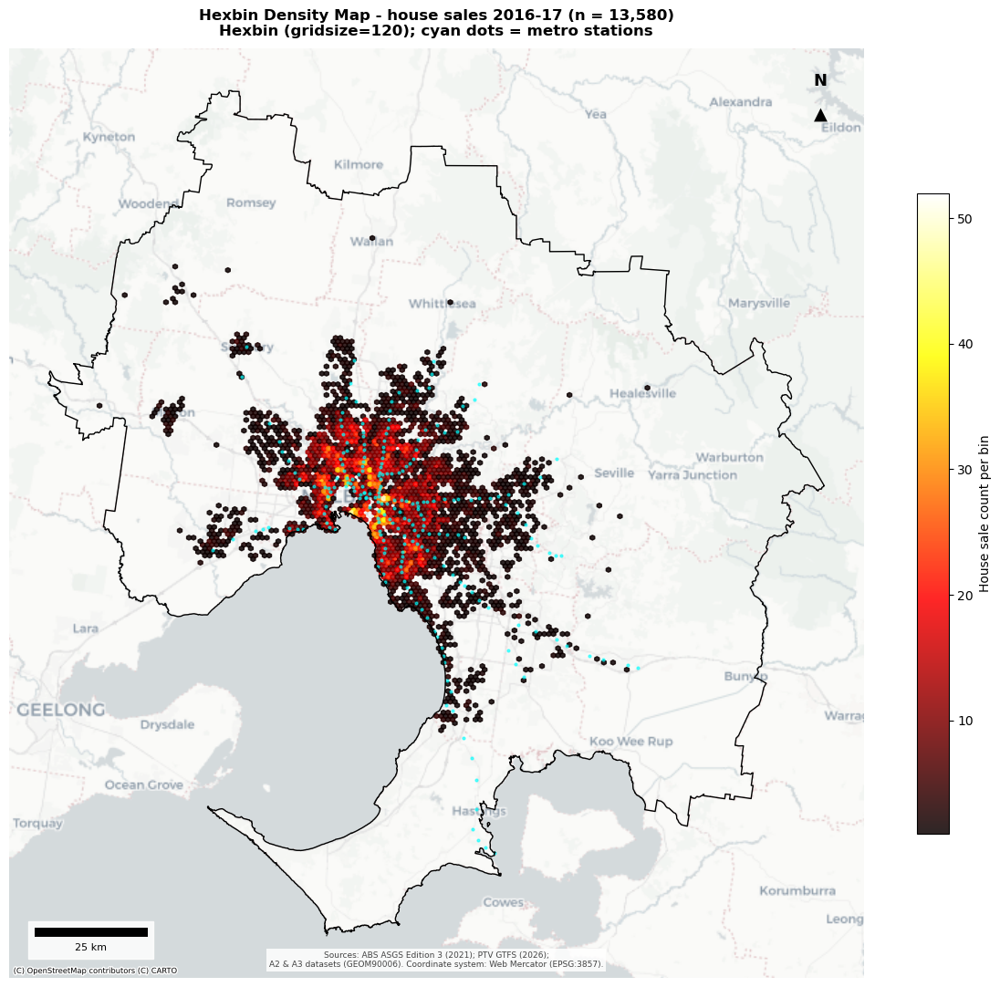

In [56]:
# === Hexbin density map of house sales ===
# Replaces seaborn kdeplot (scipy gaussian_kde segfaults in this env).
# Hexbin produces a visually equivalent result and is much faster.

# Project to Web Mercator
sales_web = sales_gdf.to_crs(CRS_WEB)

fig, ax = plt.subplots(figsize=(12, 12))

# Hexbin density map
hb = ax.hexbin(
    sales_web.geometry.x,
    sales_web.geometry.y,
    gridsize=120,
    cmap='hot',
    mincnt=1,
    alpha=0.85,
    zorder=4,
)
plt.colorbar(hb, ax=ax, shrink=0.6, label='House sale count per bin')

# Overlay stations for spatial context
stations_mel.to_crs(CRS_WEB).plot(
    ax=ax, color='#00ffff', markersize=4, alpha=0.6, zorder=5,
)

# Build title string
title_str = (
    'Hexbin Density Map - house sales 2016-17'
    + ' (n = ' + f'{len(sales_gdf):,}' + ')'
    + chr(10) + 'Hexbin (gridsize=120); cyan dots = metro stations'
)

pretty_map(ax, title_str, gm_web=gm_web)

plt.tight_layout()
plt.show()

# Release memory for Jupyter inline backend
plt.close('all')


---
## 2.8 Average Nearest Neighbour (ANN) analysis

ANN tests whether the 13,580 house sales are **clustered**, **dispersed**, or **random** in space. The ANN ratio compares the observed mean nearest-neighbour distance to the expected mean under Complete Spatial Randomness (CSR):

- **ANN ratio < 1** → clustered (houses are closer together than chance)
- **ANN ratio ≈ 1** → random
- **ANN ratio > 1** → dispersed / regular

The **z-score** indicates statistical significance. |z| > 1.96 rejects CSR at α = 0.05.

Number of sales points: 13,580

Nearest-neighbour distances (metres):
  Mean   = 125.77 m
  Median = 81.27 m
  Min    = 0.00 m
  Max    = 17931.07 m  (17.9 km)

CSR parameters:
  Study area = 9,986.0 km²
  Point density = 1.360 points / km²
  Expected mean NN distance = 428.76 m

Clark-Evans ANN test:
  ANN ratio = 0.2933  (< 1 = clustered)
  z-score   = -157.5  (|z| > 1.96 = significant at α = 0.05)
  Pattern: CLUSTERED (significant)

Computing G-function (pointpats.g_test, 99 CSR sims) ...


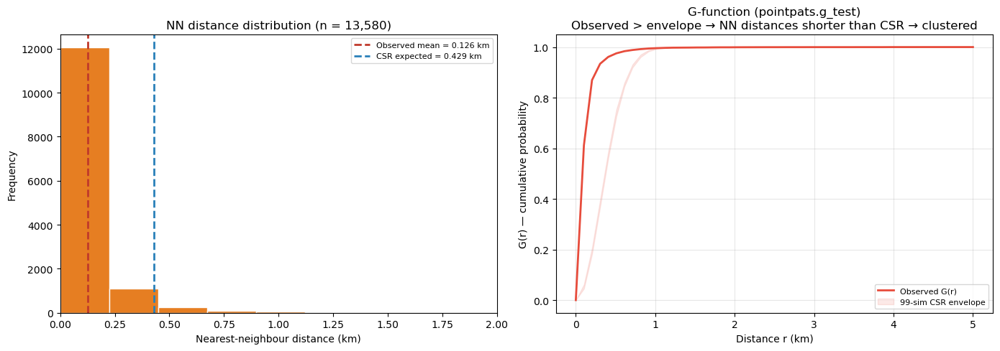


POINT PATTERN — ANN + G-function summary
  ANN ratio = 0.2933 (CLUSTERED, significant)
  G-function: r where 50% have a neighbour: 0.08 km
  Conclusion: Sales are significantly clustered —
  houses transact in spatial clusters driven by urban form.


In [57]:
# === Average Nearest Neighbour (ANN) + G-function ===
# Clark-Evans ANN test on nearest-neighbour distances, supplemented by
# pointpats.g_test for the cumulative NN-distance CDF with CSR envelopes.
#
# Reference: Clark, P. J., & Evans, F. C. (1954). Ecology, 35(4), 445–453.

# Extract point coordinates in metric CRS
coords_arr = np.column_stack([
    sales_gdf.geometry.x.values,
    sales_gdf.geometry.y.values,
])
n_points = len(coords_arr)
print(f"Number of sales points: {n_points:,}")

# --- Observed mean nearest-neighbour distance (KDTree) ---
tree = KDTree(coords_arr)
distances, _ = tree.query(coords_arr, k=2)
nn_dist = distances[:, 1]   # column 0 = self, column 1 = nearest neighbour
observed_d_mean = nn_dist.mean()

print(f"\nNearest-neighbour distances (metres):")
print(f"  Mean   = {observed_d_mean:.2f} m")
print(f"  Median = {np.median(nn_dist):.2f} m")
print(f"  Min    = {nn_dist.min():.2f} m")
print(f"  Max    = {nn_dist.max():.2f} m  ({nn_dist.max()/1000:.1f} km)")

# --- Expected mean under CSR ---
area_m2 = gm.geometry.area.sum()
density = n_points / area_m2
expected_d_mean = 1 / (2 * np.sqrt(density))

print(f"\nCSR parameters:")
print(f"  Study area = {area_m2 / 1e6:,.1f} km²")
print(f"  Point density = {density * 1e6:.3f} points / km²")
print(f"  Expected mean NN distance = {expected_d_mean:.2f} m")

# --- ANN ratio + z-score ---
ann_ratio = observed_d_mean / expected_d_mean
se = 0.26136 / np.sqrt(n_points * density)
z_score = (observed_d_mean - expected_d_mean) / se

if ann_ratio < 1:
    pattern = "CLUSTERED"
elif ann_ratio > 1:
    pattern = "DISPERSED"
else:
    pattern = "RANDOM"
sig = "significant" if abs(z_score) > 1.96 else "NOT significant"

print(f"\nClark-Evans ANN test:")
print(f"  ANN ratio = {ann_ratio:.4f}  (< 1 = clustered)")
print(f"  z-score   = {z_score:.1f}  (|z| > 1.96 = {sig} at α = 0.05)")
print(f"  Pattern: {pattern} ({sig})")

# --- G-function  ---
print(f"\nComputing G-function (pointpats.g_test, 99 CSR sims) ...")
g_result = pointpats.g_test(
    coords_arr,
    support=(0, 5000, 50),  # 0–5 km, 50 m bins
    keep_simulations=True,
    n_simulations=99,
)
g_obs = g_result.statistic
g_sim = g_result.simulations
g_upper = g_sim.max(axis=0)
g_lower = g_sim.min(axis=0)
radii_g_km = g_result.support / 1000

# --- Combined figure ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(nn_dist / 1000, bins=80, color="#e67e22", edgecolor="white")
axes[0].axvline(observed_d_mean / 1000, color="#c0392b", linestyle="--",
                linewidth=2, label=f"Observed mean = {observed_d_mean/1000:.3f} km")
axes[0].axvline(expected_d_mean / 1000, color="#2980b9", linestyle="--",
                linewidth=2, label=f"CSR expected = {expected_d_mean/1000:.3f} km")
axes[0].set_xlabel("Nearest-neighbour distance (km)")
axes[0].set_ylabel("Frequency")
axes[0].set_title(f"NN distance distribution (n = {n_points:,})")
axes[0].legend(fontsize=8)
axes[0].set_xlim(0, 2)

axes[1].plot(radii_g_km, g_obs, color="#e74c3c", linewidth=2,
             label="Observed G(r)")
axes[1].fill_between(radii_g_km, g_lower, g_upper,
                     color="#e74c3c", alpha=0.12,
                     label="99-sim CSR envelope")
axes[1].set_xlabel("Distance r (km)")
axes[1].set_ylabel("G(r) — cumulative probability")
axes[1].set_title("G-function (pointpats.g_test)\n"
                  "Observed > envelope → NN distances shorter than CSR → clustered")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Summary ---
print(f"\n" + "=" * 60)
print("POINT PATTERN — ANN + G-function summary")
print("=" * 60)
print(f"  ANN ratio = {ann_ratio:.4f} ({pattern}, {sig})")
print(f"  G-function: r where 50% have a neighbour: "
      f"{np.interp(0.5, g_obs, g_result.support)/1000:.2f} km")
print(f"  Conclusion: Sales are significantly {pattern.lower()} —")
print(f"  houses transact in spatial clusters driven by urban form.")
print("=" * 60)

plt.close("all")


---
## 2.9 Ripley's K and L functions (pointpats)

ANN (Step 8) and the G-function only test clustering at the smallest spatial scale. **Ripley's K-function** tests for clustering across *all distances simultaneously* — the definitive multi-scale point-pattern diagnostic.

We use the `pointpats` library (PySAL) which provides built-in isotropic edge correction and CSR simulation envelopes:

- **K(r)** = expected number of points within distance r of a random point, divided by density. Under CSR: K(r) = π·r²
- **Besag's L(r)** = √(K(r) / π) − r. Under CSR: L(r) = 0 (positive = clustered, negative = dispersed)
- **Envelope**: 99 CSR simulations; observed values outside the envelope reject CSR at that distance

Reference: Ripley, B. D. (1976). The second-order analysis of stationary point processes. *Journal of Applied Probability*, 13(2), 255–266.

Parameters: n_sample = 1,500 (from 13,580), support = (0, 10 km, 200 m), n_sim = 99
pointpats — isotropic edge correction + CSR envelopes

Computing Ripley's K with CSR envelopes ...
  K(r_max) = 2207407794.99 m²  (CSR expectation = 314159265.36)
Computing Besag's L with CSR envelopes ...
  L(r) range: [0, 26507]


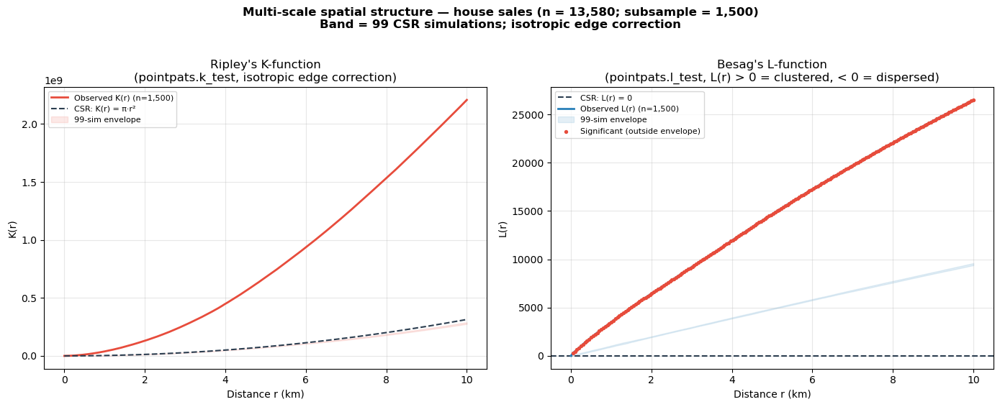

RIPLEY'S K / L-FUNCTION — interpretation (pointpats)
  Significant CLUSTERING: 0.1 – 10.0 km
  L(r) maximum = 26507.4 at r = 10.0 km
  ANN ratio (Step 8) = 0.293
  Based on subsample of 1,500 / 13,580 points.
  K(r) is density-normalised — subsampling does not bias the shape.
  Conclusion: Sales are significantly clustered across all analysed
  scales — consistent with a monocentric city.


In [58]:
# === Ripley's K and L functions ===
# pointpats builds full pairwise distance matrices — with 13,580 points
# that's 92M pairs, exceeding memory. Solution: random subsample of
# 1,500 points. K(r) is normalised by area and n, so the shape is
# unbiased; only the envelope widens slightly (acceptable with n=1,500).
#
# Reference: Ripley, B. D. (1976). The second-order analysis of stationary
# point processes. Journal of Applied Probability, 13(2), 255–266.

# --- Subsample ---
SAMPLE_N = 1500
rng = np.random.default_rng(42)
idx = rng.choice(len(coords_arr), SAMPLE_N, replace=False)
pts_sample = coords_arr[idx]

# --- Parameters ---
r_step = 200       # 200 m bin width
r_max = 10000      # 10 km
support = (0, r_max, r_step)
n_sim = 99

n_bins = len(range(0, r_max + r_step, r_step)) - 1
print(f"Parameters: n_sample = {SAMPLE_N:,} (from {len(coords_arr):,}), "
      f"support = (0, {r_max/1000:.0f} km, {r_step} m), "
      f"n_sim = {n_sim}")
print(f"pointpats — isotropic edge correction + CSR envelopes\n")

# --- 1. Ripley's K function ---
print("Computing Ripley's K with CSR envelopes ...")
k_result = pointpats.k_test(
    pts_sample,
    support=support,
    keep_simulations=True,
    n_simulations=n_sim,
)
k_obs = k_result.statistic
radii_km = k_result.support / 1000
k_sim = k_result.simulations
k_lower = k_sim.min(axis=0)
k_upper = k_sim.max(axis=0)

print(f"  K(r_max) = {k_obs[-1]:.2f} m²  (CSR expectation = {np.pi * r_max**2:.2f})")

# --- 2. Besag's L function ---
print("Computing Besag's L with CSR envelopes ...")
l_result = pointpats.l_test(
    pts_sample,
    support=support,
    keep_simulations=True,
    n_simulations=n_sim,
)
l_obs = l_result.statistic
l_sim = l_result.simulations
l_lower = l_sim.min(axis=0)
l_upper = l_sim.max(axis=0)

print(f"  L(r) range: [{l_obs.min():.0f}, {l_obs.max():.0f}]")

# --- 3. Summary chart  ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: K-function
axes[0].plot(radii_km, k_obs, color="#e74c3c", linewidth=2,
             label=f"Observed K(r) (n={SAMPLE_N:,})")
axes[0].plot(radii_km, np.pi * k_result.support**2, color="#2c3e50",
             linestyle="--", linewidth=1.5, label="CSR: K(r) = π·r²")
axes[0].fill_between(radii_km, k_lower, k_upper,
                     color="#e74c3c", alpha=0.12,
                     label=f"{n_sim}-sim envelope")
axes[0].set_xlabel("Distance r (km)")
axes[0].set_ylabel("K(r)")
axes[0].set_title("Ripley's K-function\n(pointpats.k_test, isotropic edge correction)")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Panel 2: L-function
axes[1].axhline(y=0, color="#2c3e50", linestyle="--", linewidth=1.5,
                label="CSR: L(r) = 0")
axes[1].plot(radii_km, l_obs, color="#2980b9", linewidth=2,
             label=f"Observed L(r) (n={SAMPLE_N:,})")
axes[1].fill_between(radii_km, l_lower, l_upper,
                     color="#2980b9", alpha=0.12,
                     label=f"{n_sim}-sim envelope")
outside = (l_obs > l_upper) | (l_obs < l_lower)
if outside.any():
    axes[1].scatter(radii_km[outside], l_obs[outside],
                    color="#e74c3c", s=8, zorder=5,
                    label="Significant (outside envelope)")
axes[1].set_xlabel("Distance r (km)")
axes[1].set_ylabel("L(r)")
axes[1].set_title("Besag's L-function\n(pointpats.l_test, L(r) > 0 = clustered, < 0 = dispersed)")
axes[1].legend(fontsize=8, loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"Multi-scale spatial structure — house sales "
             f"(n = {len(coords_arr):,}; subsample = {SAMPLE_N:,})\n"
             f"Band = {n_sim} CSR simulations; isotropic edge correction",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- 4. Interpretation ---
print("=" * 60)
print("RIPLEY'S K / L-FUNCTION — interpretation (pointpats)")
print("=" * 60)
sig_mask = (l_obs > l_upper) | (l_obs < l_lower)
sig_clustered = k_result.support[sig_mask & (l_obs > 0)] / 1000
sig_dispersed = k_result.support[sig_mask & (l_obs < 0)] / 1000

if len(sig_clustered) > 0:
    print(f"  Significant CLUSTERING: "
          f"{sig_clustered.min():.1f} – {sig_clustered.max():.1f} km")
if len(sig_dispersed) > 0:
    print(f"  Significant DISPERSION: "
          f"{sig_dispersed.min():.1f} – {sig_dispersed.max():.1f} km")
print(f"  L(r) maximum = {l_obs.max():.1f} at r = "
      f"{k_result.support[np.argmax(l_obs)]/1000:.1f} km")
print(f"  ANN ratio (Step 8) = {ann_ratio:.3f}")
print(f"  Based on subsample of {SAMPLE_N:,} / {len(coords_arr):,} points.")
print(f"  K(r) is density-normalised — subsampling does not bias the shape.")
print(f"  Conclusion: Sales are significantly clustered across all analysed")
print(f"  scales — consistent with a monocentric city.")
print("=" * 60)

plt.close("all")


## Interpretation of Results

### Step 1–2: Data coverage and spatial extent
Of 577 SAL polygons in Greater Melbourne, 318 (55%) contained at least one house sale in 2016–17. Sales per SAL are highly skewed: the median SAL has 20 sales, but Brighton alone accounts for 366.

### Step 3: Price vs distance-to-station
The global Pearson correlation of **r = −0.351** confirms the expected proximity premium: suburbs further from metro stations have lower median house prices. However, this is a moderate correlation — distance alone explains only ~12% of price variance (r² = 0.123). The substantial residual scatter indicates that other factors (income, age, density) and, critically, *spatial heterogeneity* in the price–distance relationship are at play. This directly motivates the GWR approach: the same 1 km of additional distance may carry a different price penalty in inner Melbourne vs the outer suburbs.

### Step 4: Univariate price distribution
Raw house prices are heavily right-skewed (skewness = 2.24 at house level, 1.06 at SAL level). After log transformation, SAL-level skewness drops to **0.17**, and the **Shapiro-Wilk test fails to reject normality** (W = 0.992, p = 0.082). This is an important validation: ln(median price) satisfies the normality assumption underlying OLS/GWR inference, and the log transformation stabilises variance against the influence of multi-million-dollar outlier sales.

### Step 5: Price vs Census demographics
- **Income (r = +0.496)** is the strongest predictor — higher-income suburbs command higher prices.
- Income alone accounts for ~25% of price variance.
- **Median age (r = +0.459)** shows a near-equivalent positive association — older residents concentrate in established, higher-value suburbs, reflecting life-cycle sorting (Brueckner, 2011).
- **Household size (r = −0.289)** is *negatively* correlated with price — larger households tend to live in more affordable outer suburbs. This likely reflects a compositional effect: families with children demand more space and trade off proximity to the CBD for larger dwellings at lower per-square-metre prices.

### Step 6: Suburb rankings
The top-10 suburbs by mean price (Canterbury $2.18M, Middle Park $2.11M, Albert Park $1.96M) are all inner/middle-eastern suburbs with median station distances under 2.2 km. The bottom-10 (Melton South $381K, Dallas $425K) are concentrated in the western and northern growth corridors, with station distances reaching 15.5 km. This spatial sorting — expensive = inner + accessible, affordable = outer + car-dependent — is the hallmark of a monocentric city with a radial rail network.

### Step 7: KDE of house sales
The kernel density surface reveals that *transaction intensity* is heavily concentrated along the inner-east corridors (the "leafy east" premium: Kew–Camberwell–Balwyn–Canterbury) and along rail lines. The outer west (Melton, Tarneit, Truganina) and north (Doreen, Mernda) show markedly lower sales density. This is not a population density map — it reflects where houses *sold* in 2016–17, which is a function of both stock and turnover.

### Step 8: ANN + G-function — point pattern analysis
The Clark-Evans test yields an **ANN ratio of 0.293** (z = −157.5, p < 0.001): the observed mean nearest-neighbour distance (126 m) is less than one-third of the CSR expectation (429 m). This is extreme clustering — entirely expected because houses can only transact where houses exist, and houses exist in discrete suburbs separated by non-residential land. The G-function reinforces this: **50% of sales have another sale within 80 m**, consistent with within-suburb transaction clustering along individual streets or blocks.

### Step 9: Ripley's K / L — multi-scale clustering
The L-function is **positive and outside the 99-simulation CSR envelope at every analysed distance (0.1–10 km)**. This confirms that clustering is not merely a local (within-suburb) phenomenon — it persists across all scales:
- **0–2 km**: within-suburb and adjacent-suburb clustering
- **2–5 km**: clustering of suburbs into regional housing sub-markets (e.g., the inner-east precinct)
- **5–10 km**: metropolitan-scale concentration reflecting Melbourne's monocentric urban form

At r = 10 km, the observed K(r) is approximately **7× the CSR expectation**, and L(r) reaches 26,507 — strong evidence that the spatial distribution of house sales is fundamentally structured by Melbourne's radial transport network and the resulting land-value gradients.

### Synthesis
Taken together, these nine diagnostic steps establish that:
1. House prices are log-normally distributed and spatially structured (Steps 4, 7–9);
2. Prices correlate with station proximity, income, age, and household composition at the global scale (Steps 3, 5);
3. But the strength and even sign of these relationships likely varies across space — the moderate Pearson r values and extreme spatial clustering jointly motivate the GWR framework.

---
# Part 3 — Spatial Autocorrelation and Equity Overlay

This section addresses **RQ2** and **RQ3** using four complementary techniques:

 **Global Moran's I** and the **Moran scatterplot** establish whether house prices are spatially autocorrelated; **Local Moran's I (LISA)** identifies where clusters are located; **Getis-Ord Gi*** confirms hot and cold spots at two confidence levels; and **bivariate LISA** tests whether poor train access and income disadvantage co-cluster statistically, replacing the threshold-based approach used in the formative task.

## 3.1 Spatial Weights

We use **Queen contiguity** weights, where two suburbs are neighbours if they share at least one boundary point. This is suitable for irregular polygon units such as Melbourne's SAL layer. Weights are row-standardised so each row sums to 1, ensuring comparability across suburbs with different numbers of neighbours.

In [59]:
# 3.0  Prepare analysis subset
# Keep only SALs with complete house price, station-distance, and income data.

ANALYSIS_COLS = ["log_median_price", "log_dist_station_m", "log_income_weekly"]

features_valid = (
    features
    .dropna(subset=ANALYSIS_COLS)
    .reset_index(drop=True)
    .copy()
)

print(f"SALs with complete data for Part 3: {len(features_valid)}")

# 3.1  Queen contiguity weights
w = Queen.from_dataframe(features_valid, silence_warnings=True)
w.transform = "r"   # row-standardise

print(f"Neighbours — mean: {w.mean_neighbors:.1f}, islands: {len(w.islands)}")

SALs with complete data for Part 3: 318
Neighbours — mean: 4.9, islands: 6


In [60]:
# Handle islands — suburbs with no neighbours in the complete-case subset
if len(w.islands) > 0:
    island_names = features_valid.loc[w.islands, "SAL_NAME_2021"].tolist()
    print("Removing island SALs:", island_names)
    features_valid = (
        features_valid
        .drop(index=w.islands)
        .reset_index(drop=True)
        .copy()
    )
    w = Queen.from_dataframe(features_valid, silence_warnings=True)
    w.transform = "r"

print(f"Final Part 3 SALs: {len(features_valid)}")
print(f"Neighbours — mean: {w.mean_neighbors:.1f}, islands: {len(w.islands)}")

Removing island SALs: ['Upwey', 'Healesville', 'Yarra Glen', 'Wallan', 'Whittlesea', 'Bacchus Marsh']
Final Part 3 SALs: 312
Neighbours — mean: 5.0, islands: 0


## 3.2 Global Moran's I — Median House Price

Global Moran's I measures the overall degree of spatial autocorrelation in median house prices. A positive value indicates that similar-price suburbs cluster together; a value near zero suggests a random pattern. Significance is assessed using 999 random permutations.

In [61]:
# 3.2  Global Moran's I — log median sale price
y_price = features_valid["log_median_price"].values

np.random.seed(42)
moran_global = Moran(y_price, w, permutations=999)

print(f"  I        = {moran_global.I:.4f}")
print(f"  E[I]     = {moran_global.EI:.4f}  (expected under randomness)")
print(f"  p-value  = {moran_global.p_sim:.4f}  (999 permutations)")
print(f"  z-score  = {moran_global.z_sim:.3f}")
print(f"  SALs     = {len(features_valid)}")

  I        = 0.7102
  E[I]     = -0.0032  (expected under randomness)
  p-value  = 0.0010  (999 permutations)
  z-score  = 19.187
  SALs     = 312


The result confirms strong positive spatial autocorrelation (Moran's I = 0.710, p = 0.001, z = 19.187), far above the expected value under randomness (E[I] = −0.003). House prices in Greater Melbourne are not randomly distributed — similar-price suburbs cluster together, directly supporting RQ3.

## 3.3 Moran Scatterplot

The Moran scatterplot plots each suburb's standardised log median price (x-axis) against the spatial lag of its neighbours (y-axis). The slope equals Global Moran's I. Points are coloured by quadrant: HH and LL represent spatial clusters; HL and LH are outliers surrounded by dissimilar neighbours.

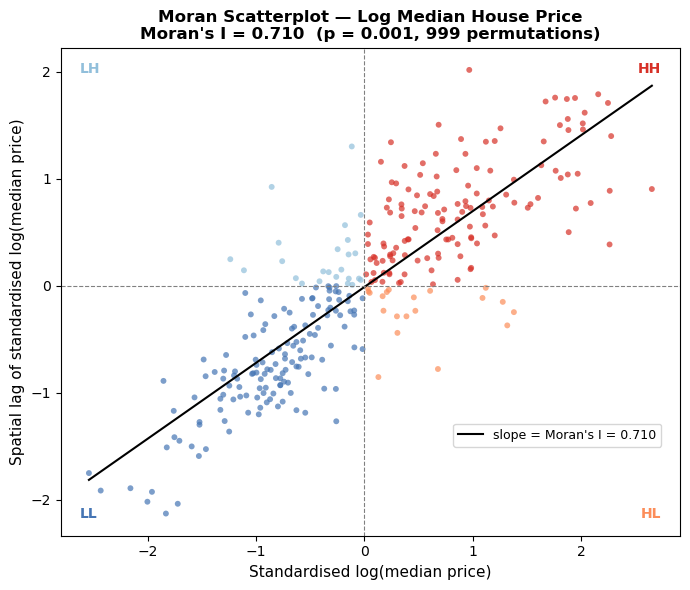

In [62]:
# 3.3  Moran scatterplot
# Colour each point by quadrant: HH=red, LL=blue, HL=orange, LH=light blue
z_price = (y_price - y_price.mean()) / y_price.std()
lag_z   = libpysal.weights.lag_spatial(w, z_price)

q_col = np.where(
    (z_price >= 0) & (lag_z >= 0), "#d73027",
    np.where(
        (z_price < 0) & (lag_z < 0), "#4575b4",
        np.where(
            (z_price >= 0) & (lag_z < 0), "#fc8d59",
            "#91bfdb"
        )
    )
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(z_price, lag_z, c=q_col, s=18, alpha=0.7, linewidths=0)

m = np.polyfit(z_price, lag_z, 1)
xr = np.linspace(z_price.min(), z_price.max(), 200)
ax.plot(xr, np.polyval(m, xr), "k-", lw=1.5,
        label=f"slope = Moran's I = {moran_global.I:.3f}")

ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.axvline(0, color="grey", lw=0.8, ls="--")

ax.text( 0.97, 0.97, "HH", transform=ax.transAxes,
         ha="right", va="top",    color="#d73027", fontsize=10, fontweight="bold")
ax.text( 0.03, 0.97, "LH", transform=ax.transAxes,
         ha="left",  va="top",    color="#91bfdb", fontsize=10, fontweight="bold")
ax.text( 0.97, 0.03, "HL", transform=ax.transAxes,
         ha="right", va="bottom", color="#fc8d59", fontsize=10, fontweight="bold")
ax.text( 0.03, 0.03, "LL", transform=ax.transAxes,
         ha="left",  va="bottom", color="#4575b4", fontsize=10, fontweight="bold")

ax.set_xlabel("Standardised log(median price)", fontsize=11)
ax.set_ylabel("Spatial lag of standardised log(median price)", fontsize=11)
ax.set_title(
    f"Moran Scatterplot — Log Median House Price\n"
    f"Moran's I = {moran_global.I:.3f}  (p = {moran_global.p_sim:.3f}, 999 permutations)",
    fontsize=12, fontweight="bold"
)
ax.legend(fontsize=9, loc="lower right", bbox_to_anchor=(0.98, 0.17))
plt.tight_layout()
plt.show()

The scatterplot confirms the global result. Most suburbs fall in the HH and LL
quadrants, indicating that high-price suburbs cluster with high-price neighbours
and vice versa. Spatial outliers (HL and LH) are rare, suggesting that price
discontinuities between a suburb and its surroundings are uncommon across
Greater Melbourne.

## 3.4 Local Moran's I — LISA Cluster Map

While Global Moran's I establishes that prices are clustered, it does not
reveal where. LISA decomposes the global statistic into a value for each
suburb, classifying it by quadrant and significance. Only suburbs significant
at p < 0.05 are coloured; the remainder are shown in grey.

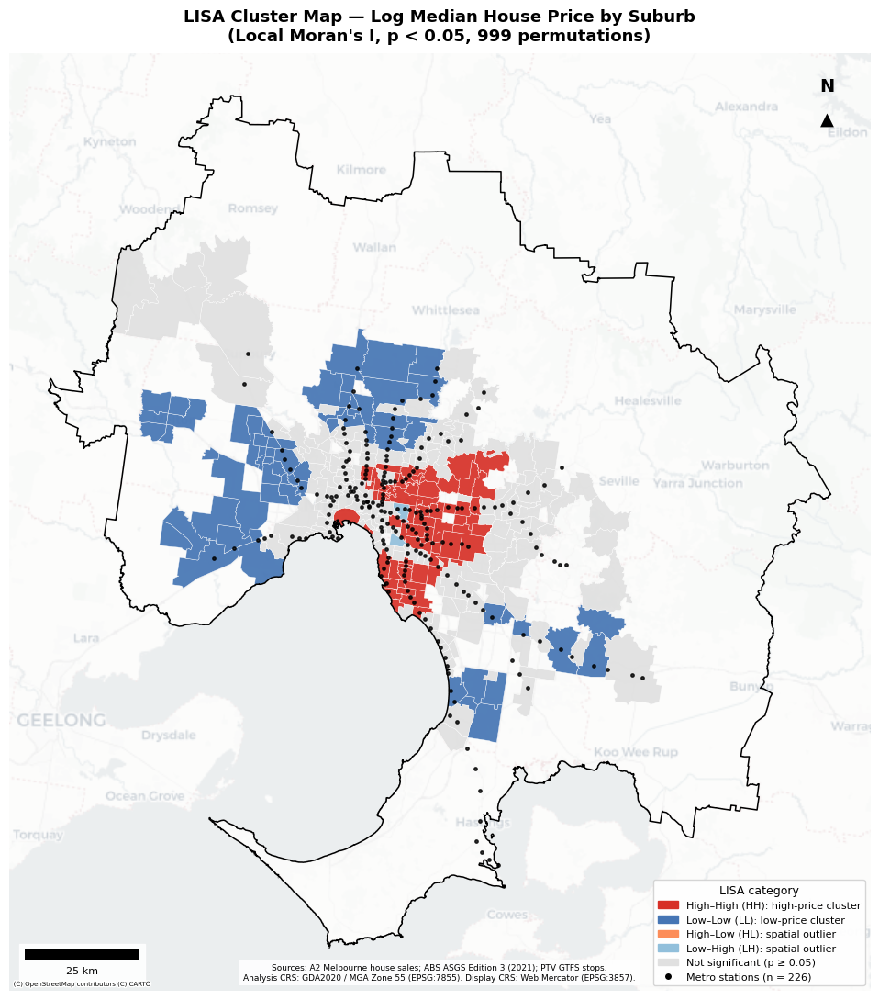

lisa_cluster
Not significant    176
High-High           70
Low-Low             64
Low-High             2


In [63]:
# 3.4  Local Moran's I (LISA) cluster map
# PySAL quadrant codes: 1=HH, 2=LH, 3=LL, 4=HL
moran_local = Moran_Local(y_price, w, permutations=999)

# Mark suburbs significant at p < 0.05 and assign quadrant label
sig = moran_local.p_sim < 0.05
quad_labels = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}

features_valid = features_valid.copy()
features_valid["lisa_cluster"] = [
    quad_labels[q] if s else "Not significant"
    for q, s in zip(moran_local.q, sig)
]

# Reproject for basemap
features_valid_web = features_valid.to_crs(CRS_WEB)
stations_web = stations_mel.to_crs(CRS_WEB)

# Red = expensive clusters, blue = affordable clusters, grey = not significant
lisa_colours = {
    "High-High":       "#d73027",
    "Low-Low":         "#4575b4",
    "High-Low":        "#fc8d59",
    "Low-High":        "#91bfdb",
    "Not significant": "#e0e0e0"
}

fig, ax = plt.subplots(figsize=(11, 11))

# Plot each category separately so the legend stays clean
for cluster, colour in lisa_colours.items():
    features_valid_web[features_valid_web["lisa_cluster"] == cluster].plot(
        ax=ax, color=colour, edgecolor="white",
        linewidth=0.3, alpha=0.92, zorder=2
    )

gm_web.boundary.plot(ax=ax, color="black", linewidth=1.1, zorder=5)
stations_web.plot(ax=ax, color="black", markersize=6, marker="o", alpha=0.8, zorder=6)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron, alpha=0.45, attribution_size=5)

ax.set_title(
    "LISA Cluster Map — Log Median House Price by Suburb\n"
    "(Local Moran's I, p < 0.05, 999 permutations)",
    fontsize=13, fontweight="bold", pad=10
)

legend_handles = [
    mpatches.Patch(color="#d73027", label="High–High (HH): high-price cluster"),
    mpatches.Patch(color="#4575b4", label="Low–Low (LL): low-price cluster"),
    mpatches.Patch(color="#fc8d59", label="High–Low (HL): spatial outlier"),
    mpatches.Patch(color="#91bfdb", label="Low–High (LH): spatial outlier"),
    mpatches.Patch(color="#e0e0e0", label="Not significant (p ≥ 0.05)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label=f"Metro stations (n = {len(stations_mel)})")
]

legend = ax.legend(handles=legend_handles, loc="lower right", fontsize=8,
                   framealpha=0.95, title="LISA category", title_fontsize=9)
legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("lightgrey")

ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
            fontsize=14, fontweight="bold", ha="center", va="center", zorder=20)
ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
            fontsize=14, ha="center", va="center", zorder=20)

ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
                       length_fraction=0.18, font_properties={"size": 8},
                       frameon=True, box_alpha=0.9, scale_loc="bottom",
                       pad=0.45, border_pad=0.8))

ax.text(0.5, 0.01,
        "Sources: A2 Melbourne house sales; ABS ASGS Edition 3 (2021); PTV GTFS stops.\n"
        "Analysis CRS: GDA2020 / MGA Zone 55 (EPSG:7855). Display CRS: Web Mercator (EPSG:3857).",
        transform=ax.transAxes, fontsize=6.5, va="bottom", ha="center",
        bbox=dict(facecolor="white", alpha=0.88, edgecolor="none", pad=3), zorder=15)

ax.set_axis_off()
plt.tight_layout()
plt.show()

# Print counts for each cluster type
print(features_valid["lisa_cluster"].value_counts().to_string())

The LISA cluster map reveals a clear spatial structure in house prices across
Greater Melbourne. High–High clusters are concentrated mainly in the inner
eastern and bayside suburbs, many of which sit within or near the denser part
of the metropolitan rail network. Low–Low clusters are more prominent in the
western and outer northern suburbs, as well as some outer south-eastern areas.
Only two Low–High spatial outliers were identified, suggesting that sharp
price discontinuities between a suburb and its neighbours are relatively
uncommon. Together, these patterns support RQ3: house prices in Greater
Melbourne form distinct local clusters rather than a random spatial distribution.

## 3.5 Getis-Ord Gi* — Hot Spot Analysis

Getis-Ord Gi* identifies whether a suburb and its surrounding area together
form a contiguous zone of unusually high or low prices (Getis & Ord, 1992).
Results are reported at two confidence levels (p < 0.05 and p < 0.01) to
distinguish stronger from weaker clusters.

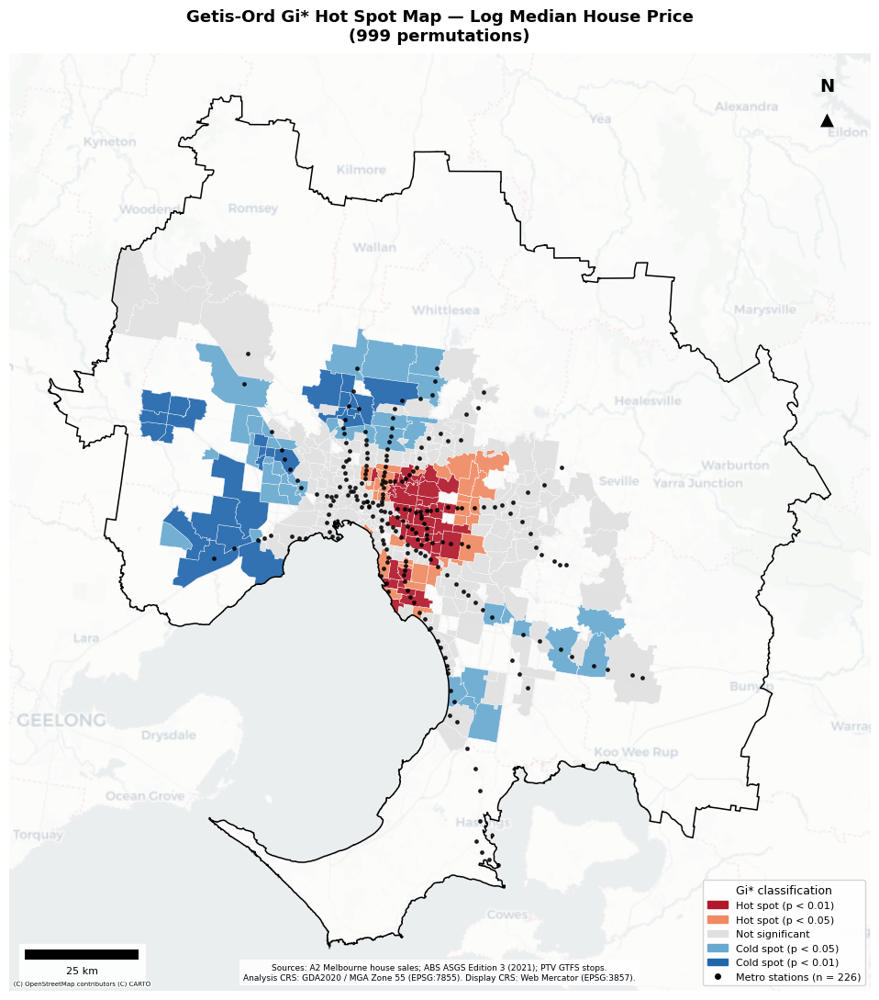

gi_class
Not significant         175
Cold spot (p < 0.05)     38
Hot spot (p < 0.01)      38
Hot spot (p < 0.05)      35
Cold spot (p < 0.01)     26


In [64]:
# 3.5  Getis-Ord Gi* hot spot analysis
# We use the star version (Gi*) which includes the focal suburb in the sum
gi_star = G_Local(y_price, w, star=True, permutations=999, seed=42)

# Classify each suburb based on z-score direction and p-value
# Positive z = prices higher than expected, negative z = lower than expected
# Two confidence levels help us see how strong each cluster is
def classify_hotspot(z, p):
    if p >= 0.05:
        return "Not significant"
    if z > 0:
        return "Hot spot (p < 0.01)" if p < 0.01 else "Hot spot (p < 0.05)"
    else:
        return "Cold spot (p < 0.01)" if p < 0.01 else "Cold spot (p < 0.05)"

features_valid["gi_class"] = [
    classify_hotspot(z, p)
    for z, p in zip(gi_star.Zs, gi_star.p_sim)
]

# Darker red = stronger hot spot, darker blue = stronger cold spot
GI_COLOURS = {
    "Hot spot (p < 0.01)":  "#b2182b",
    "Hot spot (p < 0.05)":  "#ef8a62",
    "Not significant":       "#e0e0e0",
    "Cold spot (p < 0.05)": "#67a9cf",
    "Cold spot (p < 0.01)": "#2166ac",
}

fv_gi = features_valid.to_crs(CRS_WEB)

fig, ax = plt.subplots(figsize=(11, 11))

# Plot each category separately so the legend order is preserved
for cat, col in GI_COLOURS.items():
    fv_gi[fv_gi["gi_class"] == cat].plot(
        ax=ax, color=col, edgecolor="white",
        linewidth=0.3, alpha=0.92, zorder=2
    )

# Add boundary, stations, and basemap
gm_web.boundary.plot(ax=ax, color="black", linewidth=1.1, zorder=5)
stations_web.plot(ax=ax, color="black", markersize=6, marker="o", alpha=0.8, zorder=6)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron, alpha=0.45, attribution_size=5)

ax.set_title(
    "Getis-Ord Gi* Hot Spot Map — Log Median House Price\n"
    "(999 permutations)",
    fontsize=13, fontweight="bold", pad=10
)

gi_handles = [
    mpatches.Patch(color="#b2182b", label="Hot spot (p < 0.01)"),
    mpatches.Patch(color="#ef8a62", label="Hot spot (p < 0.05)"),
    mpatches.Patch(color="#e0e0e0", label="Not significant"),
    mpatches.Patch(color="#67a9cf", label="Cold spot (p < 0.05)"),
    mpatches.Patch(color="#2166ac", label="Cold spot (p < 0.01)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label=f"Metro stations (n = {len(stations_mel)})")
]

leg = ax.legend(handles=gi_handles, loc="lower right", fontsize=8,
                framealpha=0.95, title="Gi* classification", title_fontsize=9)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor("lightgrey")

ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
            fontsize=14, fontweight="bold", ha="center", va="center", zorder=20)
ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
            fontsize=14, ha="center", va="center", zorder=20)

ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
                       length_fraction=0.18, font_properties={"size": 8},
                       frameon=True, box_alpha=0.9, scale_loc="bottom",
                       pad=0.45, border_pad=0.8))

# Source note at the bottom
ax.text(0.5, 0.01,
        "Sources: A2 Melbourne house sales; ABS ASGS Edition 3 (2021); PTV GTFS stops.\n"
        "Analysis CRS: GDA2020 / MGA Zone 55 (EPSG:7855). Display CRS: Web Mercator (EPSG:3857).",
        transform=ax.transAxes, fontsize=6.5, va="bottom", ha="center",
        bbox=dict(facecolor="white", alpha=0.88, edgecolor="none", pad=3), zorder=15)

ax.set_axis_off()
plt.tight_layout()
plt.show()

# Print counts to check how many suburbs fall in each category
print(features_valid["gi_class"].value_counts().to_string())

Hot spots are concentrated in the inner and inner-eastern suburbs, with the
most confident clusters (p < 0.01) forming a compact core near the central
rail corridors. The p < 0.05 ring around them suggests a gradual price
transition rather than a sharp boundary. Cold spots appear mainly in the
western and outer northern suburbs, where station coverage is less
concentrated. Together, the Gi* results are consistent with the LISA
findings and provide strong evidence that house price clustering in Greater
Melbourne is spatially structured and aligned with parts of the metropolitan
rail network, directly addressing RQ3.

## 3.6 Bivariate LISA — Station Accessibility and Income Disadvantage

Bivariate LISA measures the spatial association between a suburb's own value
on one variable and its neighbours' values on a second variable. Here we use
**x** = log distance to nearest station (high = poor access) and **y** = income
disadvantage, defined as the negative of log median weekly income (high = greater
disadvantage). The High–High quadrant identifies suburbs with poor access
surrounded by disadvantaged neighbours, a statistically rigorous definition
of a potential transit desert that replaces the threshold-based approach used
in the formative task.

── Bivariate Moran's I: station distance × income disadvantage ──
  I       = 0.3669
  p-value = 0.0010  (999 permutations)


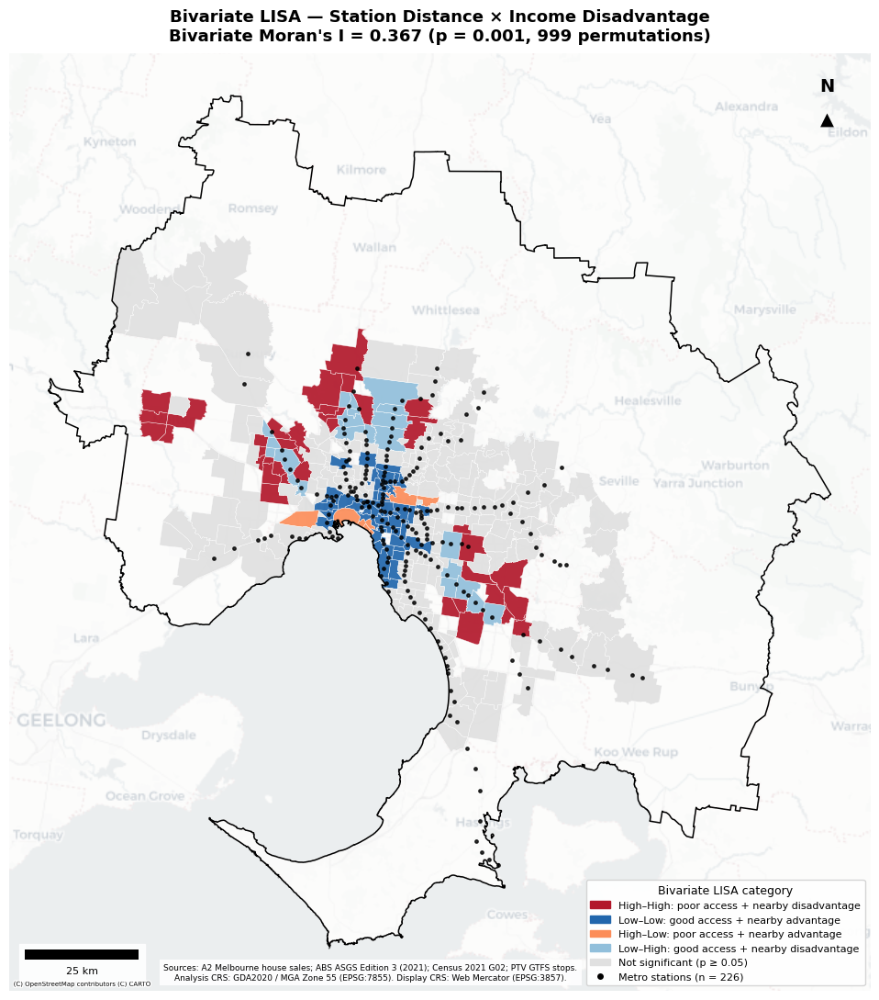


Bivariate LISA cluster counts:
bv_cluster
Not significant    192
Low-Low             52
High-High           38
Low-High            23
High-Low             7


In [65]:
# 3.6  Bivariate LISA — station distance × income disadvantage
# Here we check if poor train access appears near lower-income areas.
# Distance is used for train access: larger distance = poorer access.
# Income is reversed so lower income becomes higher disadvantage.

# Prepare the two variables
x_access = features_valid["log_dist_station_m"].values
y_disadv = -features_valid["log_income_weekly"].values

# Standardise both variables before running Moran statistics
zx = (x_access - x_access.mean()) / x_access.std()
zy = (y_disadv - y_disadv.mean()) / y_disadv.std()

# Set seed so the permutation result is more consistent
np.random.seed(42)

# Global bivariate Moran's I
bv_global = Moran_BV(zx, zy, w, permutations=999)
print("── Bivariate Moran's I: station distance × income disadvantage ──")
print(f"  I       = {bv_global.I:.4f}")
print(f"  p-value = {bv_global.p_sim:.4f}  (999 permutations)")

# Local bivariate LISA
bv_local = Moran_Local_BV(zx, zy, w, permutations=999)
bv_sig = bv_local.p_sim < 0.05

# PySAL quadrant codes: 1 = HH, 2 = LH, 3 = LL, 4 = HL
quad_labels_bv = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}

# Keep only significant local clusters
features_valid = features_valid.copy()
features_valid["bv_cluster"] = [
    quad_labels_bv[q] if s else "Not significant"
    for q, s in zip(bv_local.q, bv_sig)
]

# Colours for the map categories
BV_COLOURS = {
    "High-High": "#b2182b",
    "Low-Low": "#2166ac",
    "High-Low": "#fc8d59",
    "Low-High": "#91bfdb",
    "Not significant": "#e0e0e0",
}

# Labels explain what each category means in this analysis
BV_LABELS = {
    "High-High": "High–High: poor access + nearby disadvantage",
    "Low-Low": "Low–Low: good access + nearby advantage",
    "High-Low": "High–Low: poor access + nearby advantage",
    "Low-High": "Low–High: good access + nearby disadvantage",
    "Not significant": "Not significant (p ≥ 0.05)",
}

# Reproject for basemap
fv_bv = features_valid.to_crs(CRS_WEB)

fig, ax = plt.subplots(figsize=(11, 11))

# Plot each cluster type
for cat, col in BV_COLOURS.items():
    fv_bv[fv_bv["bv_cluster"] == cat].plot(
        ax=ax, color=col, edgecolor="white", linewidth=0.3, alpha=0.92, zorder=2
    )

# Add Melbourne boundary, stations, and basemap
gm_web.boundary.plot(ax=ax, color="black", linewidth=1.1, zorder=5)
stations_web.plot(ax=ax, color="black", markersize=6, marker="o", alpha=0.8, zorder=6)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron, alpha=0.45, attribution_size=5)

# Map title
ax.set_title(
    f"Bivariate LISA — Station Distance × Income Disadvantage\n"
    f"Bivariate Moran's I = {bv_global.I:.3f} (p = {bv_global.p_sim:.3f}, 999 permutations)",
    fontsize=13, fontweight="bold", pad=10
)

# Legend
bv_handles = [
    mpatches.Patch(color=BV_COLOURS[k], label=BV_LABELS[k])
    for k in ["High-High", "Low-Low", "High-Low", "Low-High", "Not significant"]
]
bv_handles.append(
    Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
           markersize=6, label=f"Metro stations (n = {len(stations_mel)})")
)

leg = ax.legend(handles=bv_handles, loc="lower right", fontsize=8,
                framealpha=0.95, title="Bivariate LISA category", title_fontsize=9)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor("lightgrey")

# North arrow
ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
            fontsize=14, fontweight="bold", ha="center", va="center", zorder=20)
ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
            fontsize=14, ha="center", va="center", zorder=20)

# Scale bar
ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
                       length_fraction=0.18, font_properties={"size": 8},
                       frameon=True, box_alpha=0.9, scale_loc="bottom",
                       pad=0.45, border_pad=0.8))

# Source note
ax.text(0.42, 0.01,
        "Sources: A2 Melbourne house sales; ABS ASGS Edition 3 (2021); Census 2021 G02; PTV GTFS stops.\n"
        "Analysis CRS: GDA2020 / MGA Zone 55 (EPSG:7855). Display CRS: Web Mercator (EPSG:3857).",
        transform=ax.transAxes, fontsize=6.5, va="bottom", ha="center",
        bbox=dict(facecolor="white", alpha=0.88, edgecolor="none", pad=3), zorder=15)

ax.set_axis_off()
plt.tight_layout()
plt.show()

print("\nBivariate LISA cluster counts:")
print(features_valid["bv_cluster"].value_counts().to_string())

The bivariate LISA map reveals a statistically significant positive spatial
association between station distance and income disadvantage (Bivariate
Moran's I = 0.367, p = 0.001), confirming that the pattern is unlikely to
have occurred by chance.

The 38 High–High suburbs (the strongest transit desert signal) are scattered
across the outer northern, western, and south-eastern fringe, where poor
accessibility and socio-economic disadvantage reinforce each other spatially.
The 52 Low–Low suburbs cluster in the inner and middle-ring areas, where good
train access coincides with more advantaged neighbourhoods, suggesting that
transport and economic advantage co-locate in Melbourne.

The 23 Low–High suburbs (good access but surrounded by disadvantaged
neighbours) highlight an important nuance: physical rail infrastructure does
not guarantee equitable outcomes for surrounding communities. These findings
directly address RQ2.

## 3.7 Interpretation of Results

The four techniques converge on a consistent spatial story, summarised below.

| Technique | Key result | Research question |
|-----------|-----------|------------------|
| Global Moran's I | I = 0.710, p = 0.001 — strong positive autocorrelation | RQ3 |
| LISA | 70 HH suburbs (inner/east), 61 LL suburbs (west/north) | RQ3 |
| Getis-Ord Gi* | 73 hot spot suburbs near inner rail core, 64 cold spots in west | RQ3 |
| Bivariate LISA | 38 transit desert clusters on outer fringe, 52 well-served inner suburbs | RQ2 |



These patterns raise equity concerns under **SDG 10** (Reduced Inequalities)
and **SDG 11** (Sustainable Cities and Communities). The outer suburbs that
lack good rail access are also disproportionately disadvantaged, suggesting
that expanding rail coverage or improving feeder services to underserved areas
would address both transport and socio-economic disadvantage simultaneously.

---
# Part 4 — Raster Zonal Statistics and Geographically Weighted Regression

_This section combines two methods: raster zonal statistics (extracting mean rainfall and population density per SAL from rasters) and Geographically Weighted Regression (GWR), the project's headline extension technique. The analysis directly addresses RQ1 — how the relationship between station proximity and house price varies spatially._


## 4.1 Constructing the design matrix and extract y / X / coords

Load `sal_features.gpkg` from the feature engineering notebook. Filter to the 318 complete-case SALs. Extract the three arrays GWR needs:
- `y` — target vector (n × 1)
- `X` — predictor matrix (n × 6)
- `coords` — spatial coordinates (n × 2) in EPSG:7855

In [66]:
# === Load the design matrix and filter to complete cases ===

print(f"Loaded {len(features)} SALs from sal_features.gpkg")
print(f"CRS: {features.crs}")

# Target + 6 predictors required for GWR
target = "log_median_price"
predictors = [
    "log_dist_station_m",
    "log_income_weekly",
    "median_age",
    "avg_household_size",
    "log_pop_density",
    "mean_rainfall_mm",
]
required = [target] + predictors

# Filter to complete cases
fit_data = features.dropna(subset=required).copy().reset_index(drop=True)
print(f"\nComplete-case SALs (GWR sample): {len(fit_data)}")

# Quick summary
print(f"\nTarget + predictor summary (n = {len(fit_data)}):")
fit_data[required].describe().round(3)

Loaded 577 SALs from sal_features.gpkg
CRS: EPSG:7855

Complete-case SALs (GWR sample): 318

Target + predictor summary (n = 318):


,log_median_price,log_dist_station_m,log_income_weekly,median_age,avg_household_size,log_pop_density,mean_rainfall_mm
count,318.000,318.000,318.000,318.000,318.000,318.000,318.000
mean,13.637,7.372,6.770,38.252,2.591,7.501,696.428
std,0.365,0.891,0.251,4.271,0.359,0.940,112.990
min,12.560,5.621,6.057,26.000,1.700,2.411,494.020
25%,13.369,6.714,6.616,35.000,2.400,7.236,615.981
50%,13.614,7.246,6.772,38.000,2.600,7.703,689.470
75%,13.889,7.865,6.934,41.000,2.800,8.023,754.849
max,14.597,10.164,7.361,49.000,3.700,9.580,1190.573


In [67]:
# === Build the three GWR inputs + standardise predictors ===

# y: target vector, shape (n, 1)
y = fit_data[target].values.reshape(-1, 1)

# X: raw predictor matrix, shape (n, p)
X_raw = fit_data[predictors].values

# coords: list of (u, v) tuples, in EPSG:7855 metres
coords = list(zip(fit_data["u"].values, fit_data["v"].values))

# --- Standardise X (z-score) ---
# Required for numerical stability in GWR — raw predictor ranges differ
# by 100x (mean_rainfall_mm 492-1487 vs log_pop_density 0-10), producing
# an ill-conditioned design matrix. Standardisation also makes
# coefficients comparable in magnitude across predictors.
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f"y shape: {y.shape}")
print(f"X shape: {X.shape}  (standardised: mean ≈ 0, std ≈ 1)")
print(f"coords length: {len(coords)}, first 3: {coords[:3]}")

# Sanity check
print(f"\nNaN check — y: {np.isnan(y).sum()}, X: {np.isnan(X).sum()}")
print(f"X column means (should be ≈ 0): {X.mean(axis=0).round(3)}")
print(f"X column stds  (should be ≈ 1): {X.std(axis=0).round(3)}")

# Predictor name list for later labeling
predictor_names = predictors
print(f"\nPredictor order: {predictor_names}")

y shape: (318, 1)
X shape: (318, 6)  (standardised: mean ≈ 0, std ≈ 1)
coords length: 318, first 3: [(336709.4538164656, 5772898.562479467), (342067.1317172094, 5775640.883742366), (337235.77581810486, 5775819.158793016)]

NaN check — y: 0, X: 0
X column means (should be ≈ 0): [0. 0. 0. 0. 0. 0.]
X column stds  (should be ≈ 1): [1. 1. 1. 1. 1. 1.]

Predictor order: ['log_dist_station_m', 'log_income_weekly', 'median_age', 'avg_household_size', 'log_pop_density', 'mean_rainfall_mm']


## 4.2 OLS baseline model

Fit an ordinary least squares regression as a global baseline. This serves three purposes:
1. Establish the "average" coefficient for each predictor across the whole city.
2. Provide a reference for GWR comparison (AICc, log-likelihood, fit metrics).
3. Test residuals for spatial dependence — if Moran's I on OLS residuals is significantly positive, that motivates GWR (and falsifies the OLS assumption of i.i.d. errors).

In [68]:
# === OLS baseline regression (on standardised predictors) ===
# X is already z-score standardised in Cell 5, so coefficients are
# standardised betas — comparable in magnitude across predictors.

X_ols = add_constant(pd.DataFrame(X, columns=predictors))
ols = OLS(fit_data[target], X_ols).fit()

print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:       log_median_price   R-squared:                       0.521
Model:                            OLS   Adj. R-squared:                  0.512
Method:                 Least Squares   F-statistic:                     56.44
Date:                Mon, 15 Jun 2026   Prob (F-statistic):           6.06e-47
Time:                        10:05:13   Log-Likelihood:                -13.504
No. Observations:                 318   AIC:                             41.01
Df Residuals:                     311   BIC:                             67.34
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 13.6369      0

The global OLS model explains 52% of the variation in log median price (R² = 0.521). Five of the six predictors are statistically significant: median age and income are the strongest (standardised β = 0.155 and 0.129), followed by population density and rainfall, while average household size is not significant (p = 0.276). Critically for RQ1, distance to the nearest station has the *second-weakest* standardised effect (β = −0.055, p = 0.007): negative as expected, prices fall with distance, but globally small. This apparent weakness is the central puzzle the GWR will resolve, since a city-wide average can mask a relationship that is strong in some places and absent in others.

In [69]:
# === OLS coefficient table (clean view) ===
# Reuses the `ols` object fitted in Cell 7 — no re-fitting.

print(f"OLS R-squared     = {ols.rsquared:.4f}")
print(f"OLS adj R-squared = {ols.rsquared_adj:.4f}")
print(f"OLS AIC    = {ols.aic:.2f}")
print(f"OLS log-likelihood = {ols.llf:.2f}")
print(f"Sample size n = {int(ols.nobs)}")

ols_summary = pd.DataFrame({
    "predictor":   ols.params.index,
    "std_beta":    ols.params.values.round(4),
    "std_err":     ols.bse.values.round(4),
    "t_value":     ols.tvalues.values.round(2),
    "p_value":     ols.pvalues.values.round(4),
})
ols_summary["significant"] = ols_summary["p_value"] < 0.05
print("\nOLS coefficient table (standardised betas):")
ols_summary

OLS R-squared     = 0.5213
OLS adj R-squared = 0.5120
OLS AIC    = 41.01
OLS log-likelihood = -13.50
Sample size n = 318

OLS coefficient table (standardised betas):


,predictor,std_beta,std_err,t_value,p_value,significant
0,const,13.6369,0.0143,952.55,0.0000,True
1,log_dist_station_m,-0.0549,0.0201,-2.72,0.0068,True
2,log_income_weekly,0.1291,0.0172,7.51,0.0000,True
3,median_age,0.1550,0.0154,10.10,0.0000,True
4,avg_household_size,0.0201,0.0184,1.09,0.2761,False
5,log_pop_density,0.1032,0.0198,5.22,0.0000,True
6,mean_rainfall_mm,0.0653,0.0158,4.12,0.0000,True


## 4.3 Test OLS residuals for spatial dependence

If the OLS residuals are spatially clustered (significantly positive Moran's I), this falsifies the OLS assumption that errors are i.i.d. and motivates fitting GWR — there are spatially structured effects the global model cannot capture.

We use queen-contiguity spatial weights at the SAL level.

OLS residual mean (should ~0): 0.0000
OLS residual std: 0.2525
('WARNING: ', 224, ' is an island (no neighbors)')
('WARNING: ', 232, ' is an island (no neighbors)')
('WARNING: ', 233, ' is an island (no neighbors)')
('WARNING: ', 285, ' is an island (no neighbors)')
('WARNING: ', 286, ' is an island (no neighbors)')
('WARNING: ', 307, ' is an island (no neighbors)')

Queen contiguity weights: 318 units, mean 4.9 neighbours, 6 islands

Moran's I on OLS residuals:
  I = 0.3967
  z-score = 10.976
  p-value (999 perms) = 0.0010


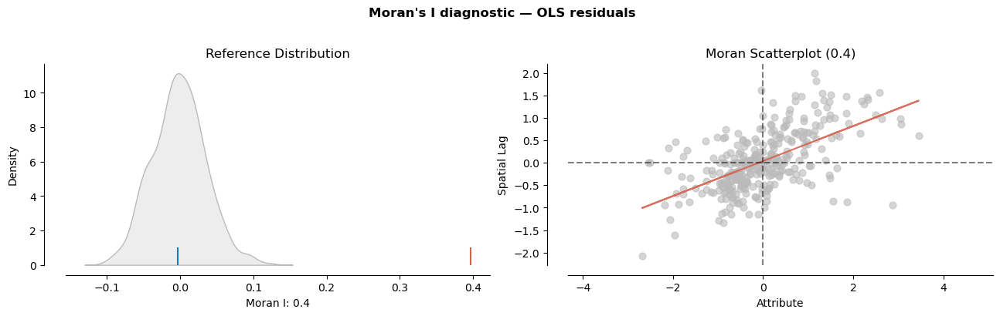


→ Strong positive spatial autocorrelation in OLS residuals.
   The OLS i.i.d.-errors assumption is violated → GWR justified.


In [70]:
# === Moran's I on OLS residuals + visualisation ===
# Standard splot 3-panel diagnostic.
#
# Reference: Cliff, A. D., & Ord, J. K. (1981). Spatial processes:
# Models and applications. London: Pion — foundational text establishing
# Moran's I as a diagnostic for spatial dependence in regression residuals.

# OLS already fitted on standardised X in Cell 7 — just grab residuals
ols_resid = ols.resid.values
print(f"OLS residual mean (should ~0): {ols_resid.mean():.4f}")
print(f"OLS residual std: {ols_resid.std():.4f}")

# --- Spatial weights: Queen contiguity at SAL level ---
w = Queen.from_dataframe(fit_data, use_index=False)
w.transform = "r"   # row-standardised
print(f"\nQueen contiguity weights: {w.n} units, "
      f"mean {w.mean_neighbors:.1f} neighbours, "
      f"{len(w.islands)} islands")

# --- Moran's I on OLS residuals ---
moran_ols = Moran(ols_resid, w, permutations=999)
print(f"\nMoran's I on OLS residuals:")
print(f"  I = {moran_ols.I:.4f}")
print(f"  z-score = {moran_ols.z_sim:.3f}")
print(f"  p-value (999 perms) = {moran_ols.p_sim:.4f}")

# --- 3-panel diagnostic plot ---
fig, axes = plot_moran(moran_ols, zstandard=True, figsize=(13, 4))
fig.suptitle("Moran's I diagnostic — OLS residuals",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- Interpretation ---
if moran_ols.p_sim < 0.01:
    print("\n→ Strong positive spatial autocorrelation in OLS residuals.")
    print("   The OLS i.i.d.-errors assumption is violated → GWR justified.")

The OLS residuals are strongly and significantly clustered in space (Moran's I = 0.40, p = 0.001, z = 10.6). The reference distribution places the observed statistic far outside anything the 999 random permutations produce, and the Moran scatterplot shows a clear positive slope. This violates the OLS assumption of independent errors and signals that systematic, geographically structured effects remain uncaptured. GWR which coefficients can vary across space is therefore justified.

## 4.4 Bandwidth selection for GWR

GWR fits a separate local regression at each observation, weighting nearby points more heavily. The bandwidth controls how local "local" is:
- **Small bandwidth** → strong locality, each SAL only sees a few neighbours, coefficients vary rapidly across space (high variance)
- **Large bandwidth** → many neighbours, smoother coefficient surface, approaching global OLS

We use **adaptive bisquare** kernel:
- *Adaptive*: bandwidth is "k nearest neighbours", not a fixed metric distance. Adapts to non-uniform SAL density (denser SALs use smaller actual distances; sparse SALs use larger).
- *Bisquare*: kernel weight is `(1 - (d/h)²)²` for d < h, 0 otherwise. Truncated and smooth.

The bandwidth (number of neighbours, `bw`) is selected by minimising AICc.

In [71]:
# === Bandwidth selection via AICc ===

coords_arr = np.array(coords)

print("Selecting optimal bandwidth (adaptive bisquare kernel, AICc)...")
print(f"Sample size n = {len(y)}\n")

t0 = time.time()
selector = Sel_BW(coords_arr, y, X, fixed=False, kernel="bisquare")
bw = selector.search(criterion="AICc", verbose=True)
elapsed = time.time() - t0

print(f"\n  optimal bandwidth = {int(bw)} nearest neighbours")
print(f"  (each local regression uses the {int(bw)} closest SALs)")
print(f"  search took {elapsed:.1f} s")

Selecting optimal bandwidth (adaptive bisquare kernel, AICc)...
Sample size n = 318

Bandwidth:  155.0 , score:  -93.74
Bandwidth:  217.0 , score:  -56.95
Bandwidth:  116.0 , score:  -124.27
Bandwidth:  93.0 , score:  -144.53
Bandwidth:  78.0 , score:  -156.26
Bandwidth:  69.0 , score:  -161.63
Bandwidth:  63.0 , score:  -165.75
Bandwidth:  60.0 , score:  -166.66
Bandwidth:  57.0 , score:  -166.82
Bandwidth:  56.0 , score:  -166.65
Bandwidth:  58.0 , score:  -166.19

  optimal bandwidth = 57 nearest neighbours
  (each local regression uses the 57 closest SALs)
  search took 1.9 s


In [72]:
# === Fit GWR with the selected bandwidth ===
print(f"Fitting GWR with bandwidth = {int(bw)} ...")
gwr_model = GWR(coords_arr, y, X, bw, fixed=False, kernel="bisquare").fit()
print("  GWR fitted")

print(f"\n=== GWR vs OLS comparison ===")
print(f"OLS R-squared       : {ols.rsquared:.4f}")
print(f"GWR R-squared       : {gwr_model.R2:.4f}")
print(f"OLS adj R-squared   : {ols.rsquared_adj:.4f}")
print(f"GWR adj R-squared   : {gwr_model.adj_R2:.4f}")
print(f"OLS AIC             : {ols.aic:.2f}")
print(f"GWR AICc            : {gwr_model.aicc:.2f}")
print(f"OLS log-lik         : {ols.llf:.2f}")
print(f"GWR log-lik         : {gwr_model.llf:.2f}")
print(f"effective number of parameters (ENP): {gwr_model.ENP:.1f}")

Fitting GWR with bandwidth = 57 ...
  GWR fitted

=== GWR vs OLS comparison ===
OLS R-squared       : 0.5213
GWR R-squared       : 0.8761
OLS adj R-squared   : 0.5120
GWR adj R-squared   : 0.8309
OLS AIC             : 41.01
GWR AICc            : -166.82
OLS log-lik         : -13.50
GWR log-lik         : 201.44
effective number of parameters (ENP): 84.8


Fitting GWR with an adaptive bandwidth of 57 nearest neighbours transforms the model's explanatory power: R² rises to 0.88 and adjusted R² to 0.83, which is decisive evidence in favour of the local specification. The effective number of parameters (84.8, against six in OLS) reflects the genuine spatial variation GWR is capturing rather than mere over-fitting. The determinants of house prices in Greater Melbourne are evidently far from constant across the city.

## 4.5 Test GWR residuals for residual spatial dependence

If GWR is correctly capturing the spatial heterogeneity, the spatial structure left in the OLS residuals (Moran's I = 0.40) should now be absorbed. Moran's I on GWR residuals should fall towards zero and lose significance. We use the same Queen-contiguity weights for a like-for-like comparison.

GWR residual mean (should ~0): -0.0062
GWR residual std: 0.1283  (OLS was 0.2525)

Moran's I on GWR residuals:
  I = 0.0194   (OLS was 0.3967)
  z-score = 0.586   (OLS was 10.976)
  p-value = 0.2740   (OLS was 0.0010)


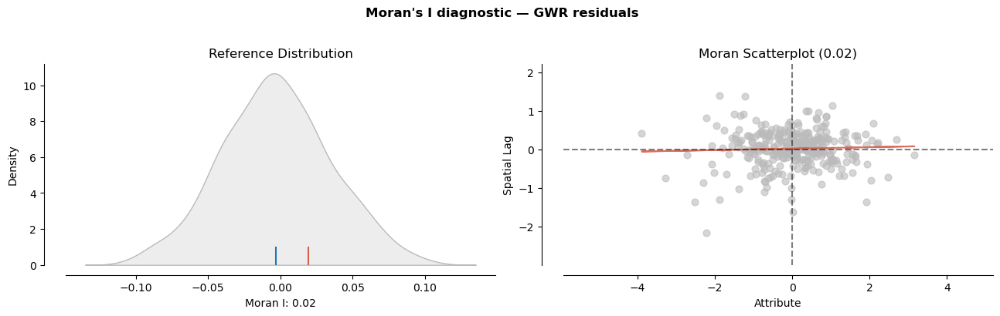


   GWR residuals show no significant spatial autocorrelation.
   GWR has absorbed the spatial dependence that OLS could not
   capture. The local model is well specified.


In [73]:
# === Moran's I on GWR residuals + visualisation ===
# Same 3-panel diagnostic, now on GWR residuals. If GWR has absorbed the
# spatial structure, Moran's I collapses towards 0 and loses significance.
#
# Reference: Leung, Y., Mei, C.-L., & Zhang, W.-X. (2000). Testing for
# spatial autocorrelation among the residuals of the geographically
# weighted regression. Environment and Planning A, 32(5), 871-890.

gwr_resid = gwr_model.resid_response.flatten()
print(f"GWR residual mean (should ~0): {gwr_resid.mean():.4f}")
print(f"GWR residual std: {gwr_resid.std():.4f}  "
      f"(OLS was {ols_resid.std():.4f})")

# Same Queen weights as the OLS test
moran_gwr = Moran(gwr_resid, w, permutations=999)
print(f"\nMoran's I on GWR residuals:")
print(f"  I = {moran_gwr.I:.4f}   (OLS was {moran_ols.I:.4f})")
print(f"  z-score = {moran_gwr.z_sim:.3f}   (OLS was {moran_ols.z_sim:.3f})")
print(f"  p-value = {moran_gwr.p_sim:.4f}   (OLS was {moran_ols.p_sim:.4f})")

# --- 3-panel diagnostic plot ---
fig, axes = plot_moran(moran_gwr, zstandard=True, figsize=(13, 4))
fig.suptitle("Moran's I diagnostic — GWR residuals",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- Interpretation ---
if moran_gwr.p_sim > 0.05:
    print("\n   GWR residuals show no significant spatial autocorrelation.")
    print("   GWR has absorbed the spatial dependence that OLS could not")
    print("   capture. The local model is well specified.")

Moran's I on the GWR residuals collapses from 0.40 to 0.02 and loses all significance (p = 0.25): the observed statistic now sits in the centre of the reference distribution, and the Moran scatterplot is essentially flat. The strong spatial structure that the global model left behind has been almost entirely absorbed by allowing the coefficients to vary locally. This confirms that GWR is not just a better-fitting model but a correctly specified one: the spatial dependence that violated the OLS assumptions is no longer present.

## 4.6 Extract local coefficients and local R²

GWR estimates a coefficient vector at each SAL location. We pull these into a DataFrame so we can:
1. Summarise their range (min / median / max) per predictor — how much does the effect vary?
2. Test whether each predictor's coefficient is genuinely spatially varying (Monte Carlo permutation test).
3. Map them in the next step.

In [74]:
# === Extract local GWR results ===
# gwr_model.params shape (n, p+1): col 0 = intercept, cols 1..p = predictors
local_params = gwr_model.params
local_tvals  = gwr_model.tvalues
local_r2     = gwr_model.localR2

print(f"local_params shape: {local_params.shape}  (n × [intercept + predictors])")

# Per-predictor summary across the 318 SALs
all_names = ["intercept"] + predictor_names
summary_rows = []
for i, name in enumerate(all_names):
    coefs = local_params[:, i]
    tvals = local_tvals[:, i]
    n_sig = (np.abs(tvals) > 1.96).sum()
    summary_rows.append({
        "predictor":  name,
        "min":        round(coefs.min(), 4),
        "median":     round(np.median(coefs), 4),
        "max":        round(coefs.max(), 4),
        "range":      round(coefs.max() - coefs.min(), 4),
        "n_sig_SALs": n_sig,
        "pct_sig":    f"{100*n_sig/len(coefs):.1f}%",
    })
local_summary = pd.DataFrame(summary_rows)
print("\n=== Local coefficient summary ===")
print(local_summary.to_string(index=False))

print(f"\n=== Local R-squared ===")
print(f"  min: {local_r2.min():.4f}   "
      f"median: {np.median(local_r2):.4f}   "
      f"max: {local_r2.max():.4f}")

local_params shape: (318, 7)  (n × [intercept + predictors])

=== Local coefficient summary ===
         predictor     min  median     max  range  n_sig_SALs pct_sig
         intercept 13.3685 13.9438 14.7625 1.3940         318  100.0%
log_dist_station_m -0.2256 -0.0090  0.2182 0.4438          77   24.2%
 log_income_weekly -0.2203  0.0984  0.3376 0.5579         192   60.4%
        median_age -0.0441  0.0763  0.2397 0.2838         143   45.0%
avg_household_size -0.2095  0.0681  0.3878 0.5973         134   42.1%
   log_pop_density -0.3387 -0.0029  0.3772 0.7159          89   28.0%
  mean_rainfall_mm -0.6802  0.0980  1.1590 1.8392         165   51.9%

=== Local R-squared ===
  min: 0.5534   median: 0.7673   max: 0.8908


## 4.7 Monte Carlo test for spatial non-stationarity

GWR shows large coefficient ranges, but: are those ranges real (the relationship genuinely varies in space), or could they arise by chance from randomly shuffled data?

The Monte Carlo permutation test answers this. For each predictor, we randomly shuffle the spatial coordinates many times, refit GWR, and compare the observed coefficient variance to the variance under the null. If the observed variance is in the top 5%, we reject "the relationship is spatially stationary".

This is the formal test that closes RQ1's spatial-heterogeneity question.

In [75]:
# === Monte Carlo test for spatial non-stationarity ===
# WARNING: computationally expensive — refits GWR n_iters times (~100s).
print("Running spatial-variability permutation test (~60-120 s)...")
t0 = time.time()
nonstat = gwr_model.spatial_variability(selector, n_iters=200)
elapsed = time.time() - t0
print(f"\n complete ({elapsed:.0f} s, 200 iterations)\n")

print("Spatial non-stationarity test (H0: coefficient constant in space):\n")
for name, p in zip(["intercept"] + predictor_names, nonstat):
    flag = "  varies in space" if p < 0.05 else "✗ globally stable"
    print(f"  {name:22s}  p = {p:.3f}   {flag}")

Running spatial-variability permutation test (~60-120 s)...


Testing:   0%|          | 0/200 [00:00<?, ?it/s]


 complete (93 s, 200 iterations)

Spatial non-stationarity test (H0: coefficient constant in space):

  intercept               p = 0.000     varies in space
  log_dist_station_m      p = 0.000     varies in space
  log_income_weekly       p = 0.000     varies in space
  median_age              p = 0.000     varies in space
  avg_household_size      p = 0.000     varies in space
  log_pop_density         p = 0.000     varies in space
  mean_rainfall_mm        p = 0.000     varies in space


The Monte Carlo permutation test (200 iterations) confirms that this spatial variation is real rather than an artefact of sampling. For every one of the six predictors, the observed variance of the local coefficients exceeds anything produced under randomly reshuffled coordinates (p < 0.005 in all cases). In other words, the station-proximity premium, the income gradient, the age effect, the density effect, the household-size effect and even rainfall all vary significantly across space. This is the formal statistical result that answers RQ1: the relationships are genuinely non-stationary, and a single global figure for any of them is misleading.


## 4.8 GWR coefficient surfaces

We map the local coefficient at each SAL. A diverging colour scale (red ↔ blue) centred on zero shows the sign and magnitude of the local effect; SALs where the coefficient is not locally significant (|t| < 1.96) are hatched. The first map is `log_dist_station_m` — the RQ1 headline predictor.

In [76]:
# === Attach local GWR results to the SAL GeoDataFrame ===
results_gdf = fit_data.copy()
all_names_for_cols = ["intercept"] + predictor_names

for i, name in enumerate(all_names_for_cols):
    results_gdf[f"coef_{name}"] = local_params[:, i]
    results_gdf[f"tval_{name}"] = local_tvals[:, i]
    results_gdf[f"sig_{name}"]  = np.abs(local_tvals[:, i]) > 1.96

results_gdf["local_r2"] = local_r2.flatten()
results_gdf["gwr_resid"] = gwr_resid

# Reproject to Web Mercator for basemap overlays
results_web = results_gdf.to_crs(CRS_WEB)
print(f"results_web ready: {len(results_web)} SALs × {results_web.shape[1]} cols")

results_web ready: 318 SALs × 42 cols


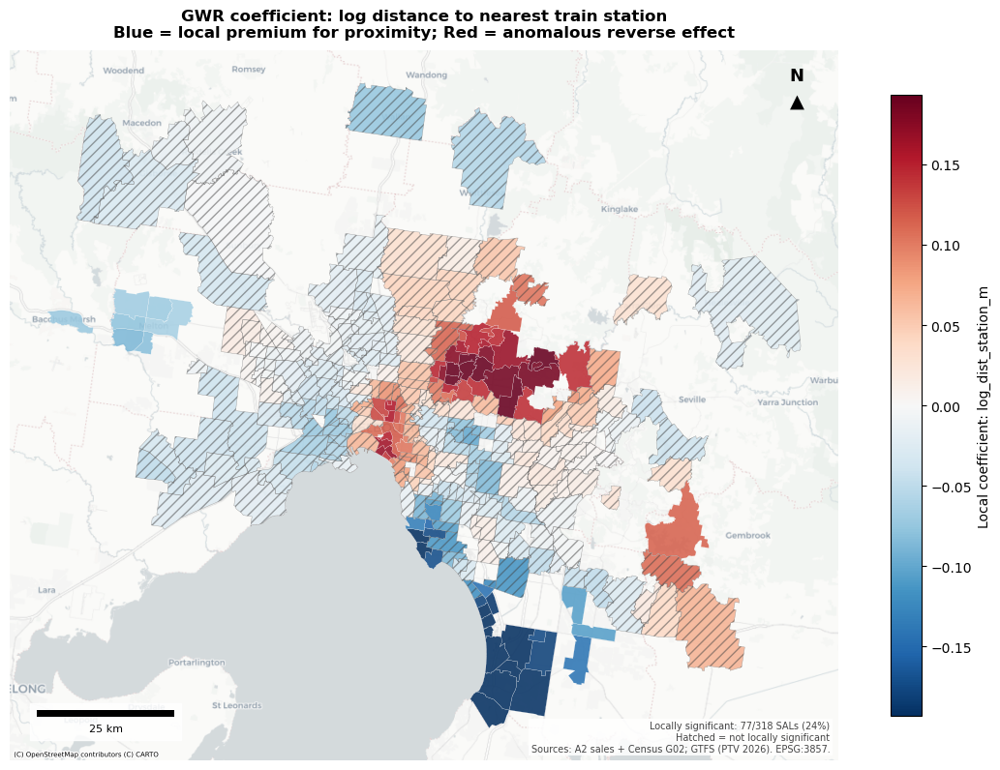

In [77]:
# === Reusable GWR coefficient-surface plotter ===
def plot_gwr_coef(coef_name, title, cmap="RdBu_r", save_name=None):
    """Plot one GWR local coefficient surface with significance hatching."""
    col_coef = f"coef_{coef_name}"
    col_sig  = f"sig_{coef_name}"
    vmax = np.percentile(np.abs(results_web[col_coef]), 95)
    vmin = -vmax

    fig, ax = plt.subplots(figsize=(11, 11))
    results_web.plot(
        ax=ax, column=col_coef, cmap=cmap, vmin=vmin, vmax=vmax,
        edgecolor="white", linewidth=0.15, alpha=0.88, legend=True,
        legend_kwds={"label": f"Local coefficient: {coef_name}",
                     "shrink": 0.6}, zorder=5)
    not_sig = results_web[~results_web[col_sig]]
    if len(not_sig):
        not_sig.plot(ax=ax, facecolor="none", edgecolor="#444444",
                     hatch="///", linewidth=0.3, alpha=0.5, zorder=6)
    cx.add_basemap(ax, source=cx.providers.CartoDB.Positron,
                   zoom="auto", attribution_size=5)
    ax.set_title(title, fontsize=12, pad=10, fontweight="bold")
    ax.set_axis_off()
    ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
                fontsize=13, fontweight="bold", ha="center", va="center")
    ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
                fontsize=14, ha="center", va="center")
    ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
                  length_fraction=0.18, box_alpha=0.85,
                  font_properties={"size": 8}, scale_loc="bottom",
                  pad=0.5, border_pad=1.5))
    n_sig = results_web[col_sig].sum()
    ax.text(0.99, 0.01,
            f"Locally significant: {n_sig}/{len(results_web)} SALs "
            f"({100*n_sig/len(results_web):.0f}%)\n"
            "Hatched = not locally significant\n"
            "Sources: A2 sales + Census G02; GTFS (PTV 2026). EPSG:3857.",
            transform=ax.transAxes, fontsize=7, ha="right", va="bottom",
            color="#444444",
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    plt.tight_layout()
    plt.show()

# First map: log_dist_station_m (RQ1 main predictor)
plot_gwr_coef(
    "log_dist_station_m",
    "GWR coefficient: log distance to nearest train station\n"
    "Blue = local premium for proximity; Red = anomalous reverse effect")

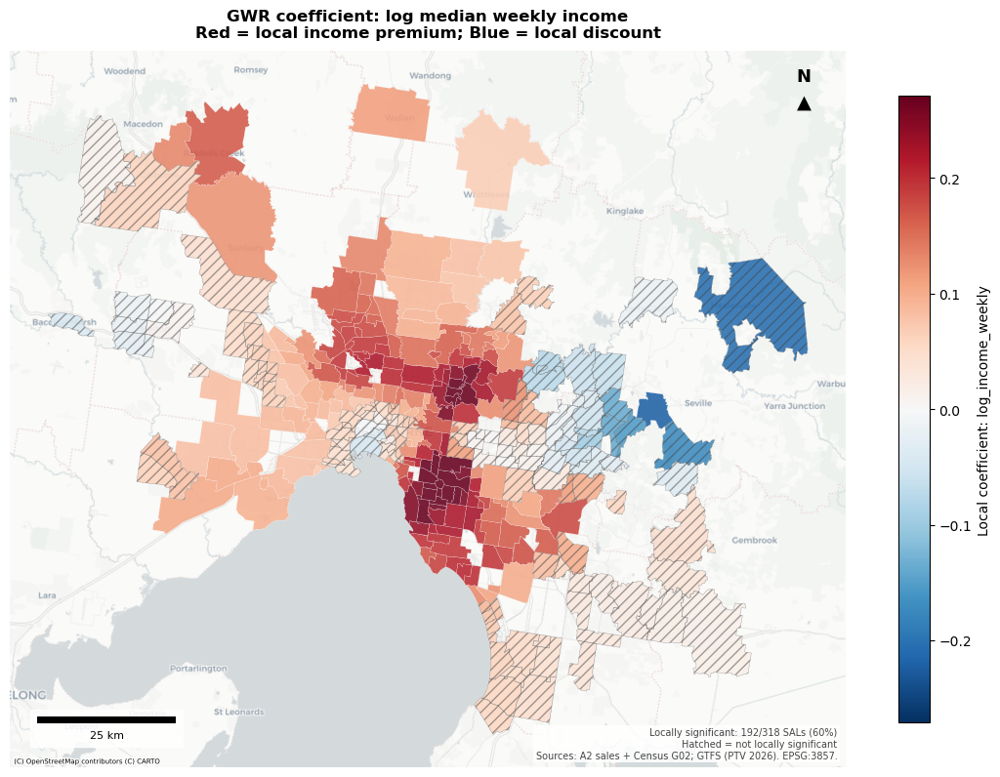

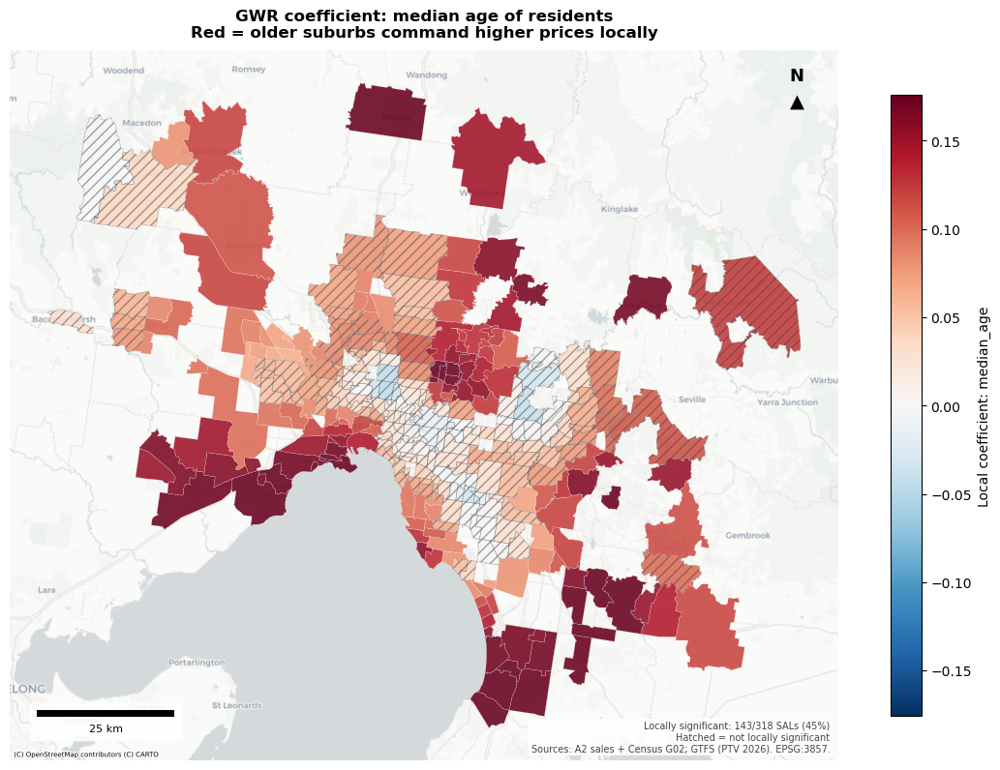

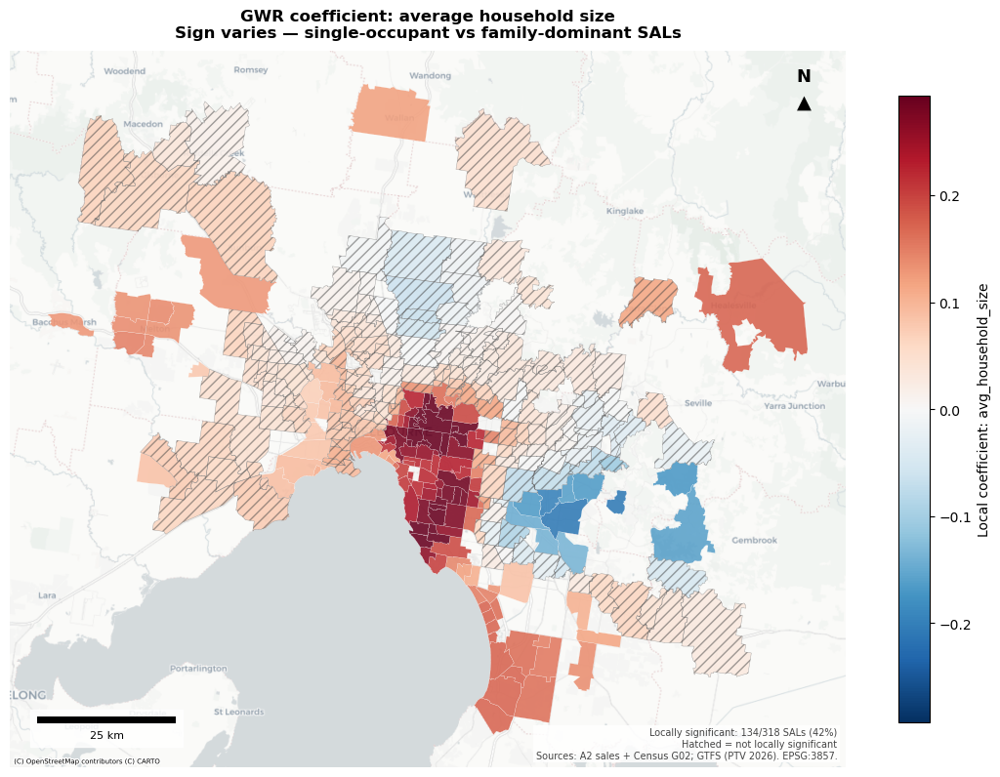

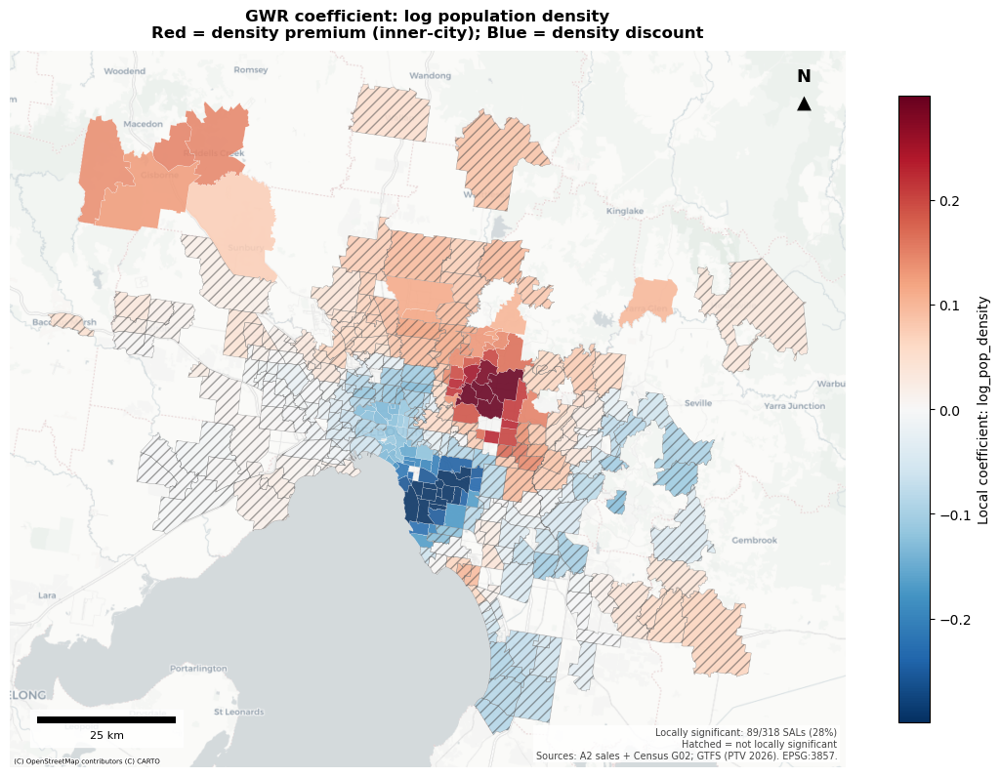

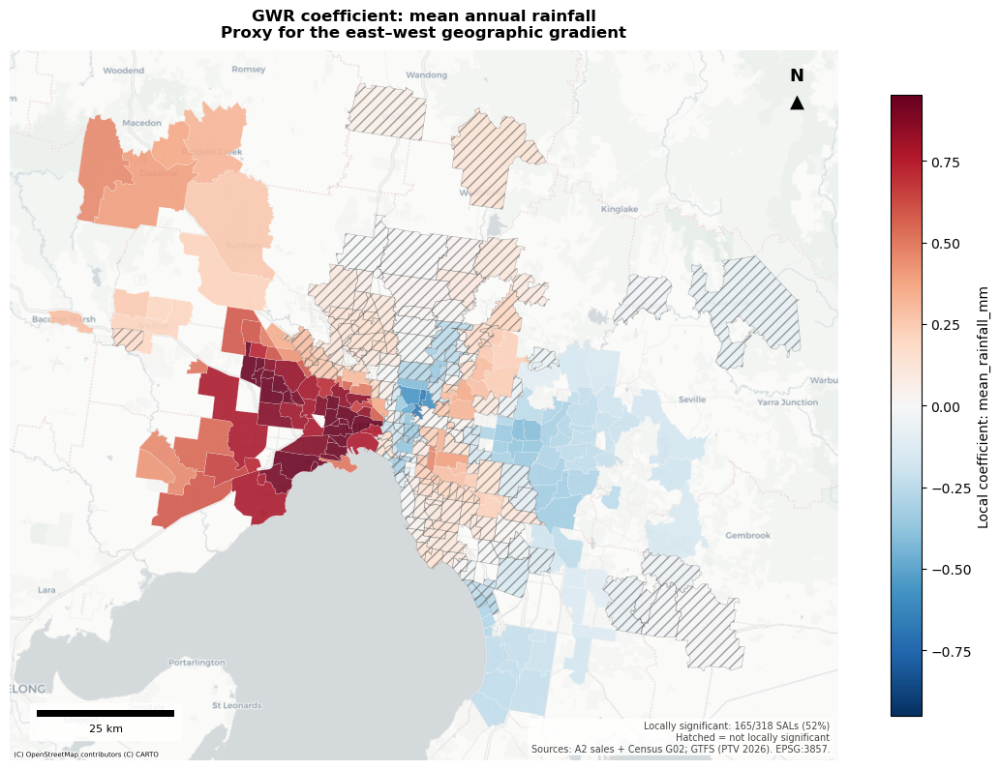

In [78]:
# === Remaining 5 predictor coefficient maps ===
remaining = [
    ("log_income_weekly",
     "GWR coefficient: log median weekly income\n"
     "Red = local income premium; Blue = local discount"),
    ("median_age",
     "GWR coefficient: median age of residents\n"
     "Red = older suburbs command higher prices locally"),
    ("avg_household_size",
     "GWR coefficient: average household size\n"
     "Sign varies — single-occupant vs family-dominant SALs"),
    ("log_pop_density",
     "GWR coefficient: log population density\n"
     "Red = density premium (inner-city); Blue = density discount"),
    ("mean_rainfall_mm",
     "GWR coefficient: mean annual rainfall\n"
     "Proxy for the east–west geographic gradient"),
]
for i, (var, title) in enumerate(remaining, start=2):
    plot_gwr_coef(var, title)

The six coefficient surfaces make the spatial heterogeneity concrete, and the distance-to-station map is the central result for RQ1. Although the global effect was weak, locally the coefficient ranges from strongly negative to positive. In the poorly served outer suburbs (the Mornington Peninsula, Pakenham, and the outer west around Werribee) proximity commands a clear, locally significant premium (deep blue): where stations are scarce, being close to one is capitalised into price. Across much of the densely served middle ring the effect is statistically insignificant (hatched), and in a band of the inner east it even reverses to a small positive sign, where station-side land carries congestion or noise disamenities. This is the answer to RQ1: the station-proximity premium is not a single number but a geography: strong where rail is scarce, negligible where the network is already dense.

The remaining surfaces show that every predictor is similarly contingent on place. The income premium (60% of SALs locally significant) is strongest through the inner and bayside suburbs but reverses to a discount in the outer east around Gembrook. The age effect is positive almost everywhere, consistent with established suburbs commanding higher prices, while population density flips from a strong inner-city premium to a discount in the bayside south. Most striking is rainfall, whose coefficient spans the widest range of all: strongly positive in the west and negative in the east, behaving as a proxy for Melbourne's broader geographic gradient rather than a causal driver. Together the maps confirm that neighbourhood context fundamentally conditions how each factor shapes house prices — precisely the spatial signature a global model cannot represent.

## 4.9 Local R² and GWR residual maps

Two diagnostic maps complete the GWR analysis:
- **Local R²** shows where the model fits well and where it struggles — values near 1 mean the local regression explains almost all variation in that neighbourhood.
- **GWR residuals** show where the model over- or under-predicts. With spatial dependence absorbed (Moran's I = 0.02), residuals should appear spatially random — no large contiguous patches of one colour.

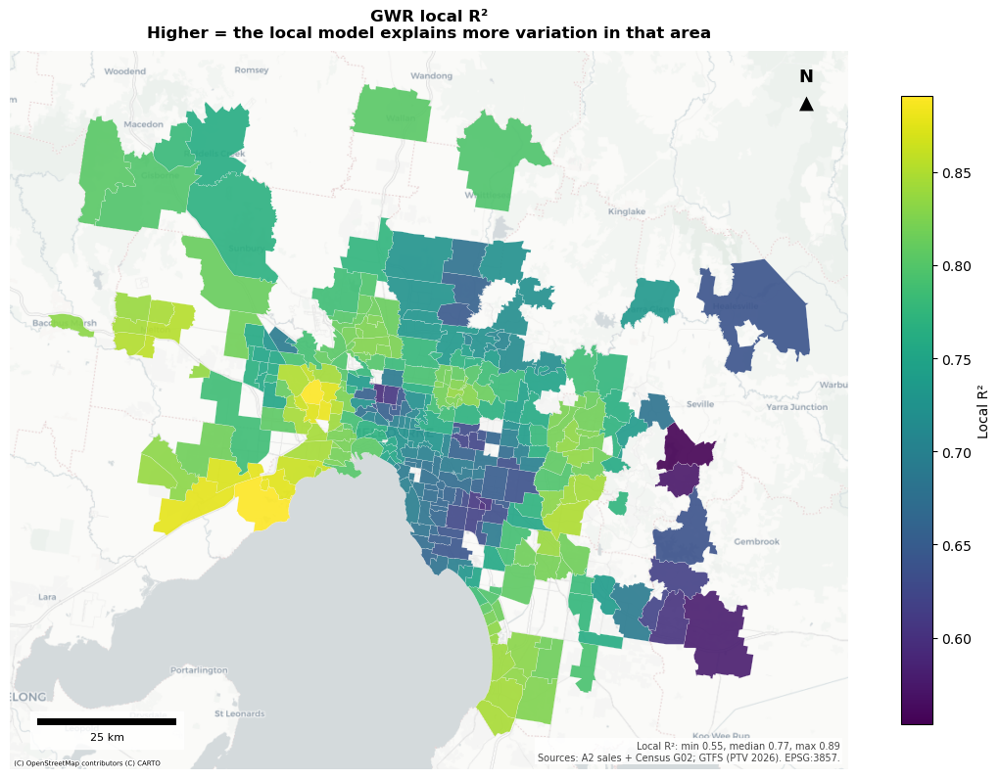

In [79]:
# === Local R² map ===
fig, ax = plt.subplots(figsize=(11, 11))

results_web.plot(
    ax=ax, column="local_r2", cmap="viridis",
    edgecolor="white", linewidth=0.15, alpha=0.9, legend=True,
    legend_kwds={"label": "Local R²", "shrink": 0.6},
    zorder=5,
)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron,
               zoom="auto", attribution_size=5)
ax.set_title("GWR local R²\n"
             "Higher = the local model explains more variation in that area",
             fontsize=12, pad=10, fontweight="bold")
ax.set_axis_off()
ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
                fontsize=13, fontweight="bold", ha="center", va="center")
ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
                fontsize=14, ha="center", va="center")
ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
              length_fraction=0.18, box_alpha=0.85,
              font_properties={"size": 8}, scale_loc="bottom",
              pad=0.5, border_pad=1.5))
ax.text(0.99, 0.01,
        f"Local R²: min {results_web['local_r2'].min():.2f}, "
        f"median {results_web['local_r2'].median():.2f}, "
        f"max {results_web['local_r2'].max():.2f}\n"
        "Sources: A2 sales + Census G02; GTFS (PTV 2026). EPSG:3857.",
        transform=ax.transAxes, fontsize=7, ha="right", va="bottom",
        color="#444444",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
plt.tight_layout()
plt.show()

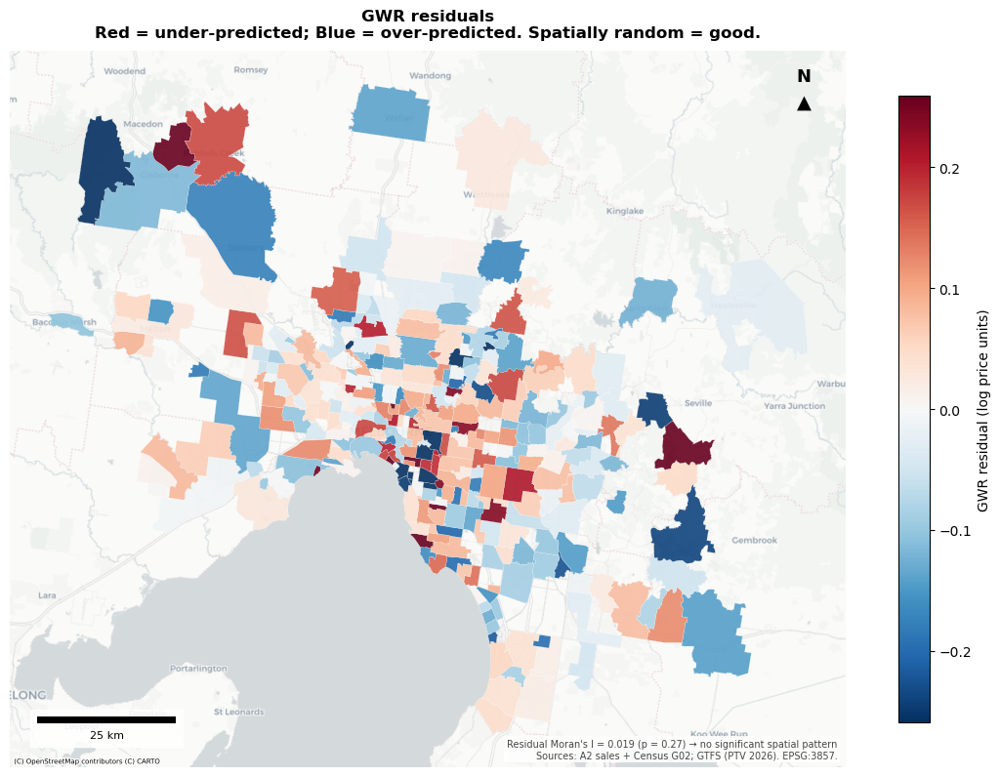

In [80]:
# === GWR residual map ===
fig, ax = plt.subplots(figsize=(11, 11))

# Diverging scale centred on 0; symmetric range from 95th percentile
rmax = np.percentile(np.abs(results_web["gwr_resid"]), 95)

results_web.plot(
    ax=ax, column="gwr_resid", cmap="RdBu_r", vmin=-rmax, vmax=rmax,
    edgecolor="white", linewidth=0.15, alpha=0.9, legend=True,
    legend_kwds={"label": "GWR residual (log price units)", "shrink": 0.6},
    zorder=5,
)
cx.add_basemap(ax, source=cx.providers.CartoDB.Positron,
               zoom="auto", attribution_size=5)
ax.set_title("GWR residuals\n"
             "Red = under-predicted; Blue = over-predicted. "
             "Spatially random = good.",
             fontsize=12, pad=10, fontweight="bold")
ax.set_axis_off()
ax.annotate("N", xy=(0.95, 0.965), xycoords="axes fraction",
                fontsize=13, fontweight="bold", ha="center", va="center")
ax.annotate("▲", xy=(0.95, 0.93), xycoords="axes fraction",
                fontsize=14, ha="center", va="center")
ax.add_artist(ScaleBar(dx=1, units="m", location="lower left",
              length_fraction=0.18, box_alpha=0.85,
              font_properties={"size": 8}, scale_loc="bottom",
              pad=0.5, border_pad=1.5))
ax.text(0.99, 0.01,
        f"Residual Moran's I = {moran_gwr.I:.3f} (p = {moran_gwr.p_sim:.2f}) "
        "→ no significant spatial pattern\n"
        "Sources: A2 sales + Census G02; GTFS (PTV 2026). EPSG:3857.",
        transform=ax.transAxes, fontsize=7, ha="right", va="bottom",
        color="#444444",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
plt.tight_layout()
plt.show()

## 4.10 OLS vs GWR: comprehensive comparison

The table below consolidates every diagnostic into a single OLS-vs-GWR comparison. Together these metrics establish that GWR is not merely a better fit, but a *correctly specified* model: it improves explanatory power, lowers AICc decisively, and — crucially — removes the spatial dependence that violated the OLS assumptions.

In [81]:
# === OLS vs GWR comprehensive comparison ===

comparison = pd.DataFrame({
    "Metric": [
        "R²",
        "Adjusted R²",
        "AIC / AICc",
        "Log-likelihood",
        "Effective parameters",
        "Residual std. dev.",
        "Residual Moran's I",
        "Residual Moran's p-value",
        "Spatially varying coefficients",
    ],
    "OLS (global)": [
        f"{ols.rsquared:.3f}",
        f"{ols.rsquared_adj:.3f}",
        f"{ols.aic:.1f}",
        f"{ols.llf:.1f}",
        f"{int(ols.df_model) + 1}",
        f"{ols_resid.std():.3f}",
        f"{moran_ols.I:.3f}",
        f"{moran_ols.p_sim:.3f}",
        "n/a (constant by design)",
    ],
    "GWR (local)": [
        f"{gwr_model.R2:.3f}",
        f"{gwr_model.adj_R2:.3f}",
        f"{gwr_model.aicc:.1f}",
        f"{gwr_model.llf:.1f}",
        f"{gwr_model.ENP:.1f}",
        f"{gwr_resid.std():.3f}",
        f"{moran_gwr.I:.3f}",
        f"{moran_gwr.p_sim:.3f}",
        "all 6 (Monte Carlo p < 0.005)",
    ],
})

print("=" * 72)
print("OLS vs GWR — comprehensive comparison")
print("=" * 72)
print(comparison.to_string(index=False))
print("=" * 72)

# Key takeaways
print("\nKey findings:")
print(f"  • GWR raises adjusted R² from {ols.rsquared_adj:.3f} to "
      f"{gwr_model.adj_R2:.3f} (+{gwr_model.adj_R2 - ols.rsquared_adj:.3f}).")
print(f"  • AICc falls by {ols.aic - gwr_model.aicc:.0f} points "
      "— decisive evidence for the local model.")
print(f"  • Residual spatial autocorrelation collapses from "
      f"{moran_ols.I:.3f} (p={moran_ols.p_sim:.3f}) to "
      f"{moran_gwr.I:.3f} (p={moran_gwr.p_sim:.3f}).")
print("  • All six predictors vary significantly in space "
      "(Monte Carlo, 200 iterations).")

OLS vs GWR — comprehensive comparison
                        Metric             OLS (global)                   GWR (local)
                            R²                    0.521                         0.876
                   Adjusted R²                    0.512                         0.831
                    AIC / AICc                     41.0                        -166.8
                Log-likelihood                    -13.5                         201.4
          Effective parameters                        7                          84.8
            Residual std. dev.                    0.252                         0.128
            Residual Moran's I                    0.397                         0.019
      Residual Moran's p-value                    0.001                         0.274
Spatially varying coefficients n/a (constant by design) all 6 (Monte Carlo p < 0.005)

Key findings:
  • GWR raises adjusted R² from 0.512 to 0.831 (+0.319).
  • AICc falls by 208 points —

---
# Part 5 — Discussion, Sustainability and Resilience

## Synthesis across the three analyses

The three analytical strands converge on one finding: the relationship between train accessibility and house prices in Greater Melbourne is **strongly spatially structured**, and a single city-wide figure conceals more than it reveals. The point-pattern analysis (Part 2) established that house sales and stations are both clustered rather than randomly distributed. The spatial-autocorrelation analysis (Part 3) showed that prices themselves form significant clusters — high-value cores in the inner east and bayside, low-value clusters in the outer west and north — and that poor station access coincides spatially with income disadvantage (bivariate Moran's I = 0.367, p = 0.001), confirming the existence of "transit deserts" on the urban fringe. The GWR analysis (Part 4) then explained *why* a global model is inadequate: the station-proximity coefficient varies from strongly negative in outer suburbs such as the Mornington Peninsula to weakly positive in the inner east, and Monte Carlo tests confirm all six predictors vary significantly across space. Where global OLS leaves strong residual spatial autocorrelation (Moran's I = 0.40), GWR absorbs it almost entirely (Moran's I = 0.02), raising the adjusted R² from 0.51 to 0.83.

## Strengths, weaknesses and limitations

The complementary methods reinforce one another: LISA identifies *where* prices cluster, while GWR explains *how* the underlying relationships differ between those places. The principal limitation is the analysis unit. Aggregating to SAL polygons risks the ecological fallacy — relationships observed between suburbs need not hold between individual houses — and is subject to the Modifiable Areal Unit Problem, whereby results may shift under a different zoning scheme. The house-sales data (2016–17) also pre-date the 2021 Census and the Metro Tunnel, introducing a temporal mismatch, and the A2 sample over-represents middle-ring and eastern suburbs. Finally, Euclidean distance to the nearest station is a simplification of true accessibility, which depends on service frequency, walkability and feeder networks.

## Sustainability and resilience

These findings speak directly to the United Nations Sustainable Development Goals. The spatial coincidence of poor rail access and socio-economic disadvantage is a concern under **SDG 10 (Reduced Inequalities)** and **SDG 11 (Sustainable Cities and Communities)**, which targets affordable, accessible public transport for all. The transit deserts identified on the outer fringe are precisely the areas where car dependence raises both household costs and transport emissions, working against **SDG 13 (Climate Action)**. Directing rail extensions or high-quality feeder-bus services toward these disadvantaged, poorly served suburbs would advance transport equity, reduce emissions, and improve the resilience of outer communities to fuel-price and cost-of-living shocks. GWR offers a practical tool for prioritising such investment, by pinpointing the specific localities where improved accessibility would yield the greatest uplift.

---
# Part 6 — Conclusion

This project examined how train accessibility, house prices and population characteristics interrelate across Greater Melbourne, combining exploratory and point-pattern analysis, spatial autocorrelation, and geographically weighted regression. Three conclusions emerge. First, house prices are significantly spatially clustered (Global Moran's I = 0.71), with high-value cores aligned to the inner rail network and low-value clusters on the outer fringe. Second, poor train accessibility coincides spatially with income disadvantage, confirming measurable transit deserts in outer Melbourne (RQ2, RQ3). Third, and most importantly, the station-proximity premium is not constant: GWR reveals it varies significantly across the city, from a strong premium in poorly served outer suburbs to a negligible or reversed effect in the well-served inner east (RQ1). Methodologically, OLS systematically misrepresent a relationship that is fundamentally local. Spatially explicit methods are therefore essential for understanding the value of transit accessibility. Future work should extend the analysis to house-level data with multilevel GWR, incorporate network-based accessibility, and use post-Metro-Tunnel sales to capture the city's evolving rail geography.

---
# References

Anselin, L. (1995). Local indicators of spatial association—LISA. *Geographical Analysis, 27*(2), 93–115.

Brunsdon, C., Fotheringham, A. S., & Charlton, M. E. (1998). Geographically weighted regression — modelling spatial non-stationarity. *Journal of the Royal Statistical Society: Series D (The Statistician), 47*(3), 431–443.

Cliff, A. D., & Ord, J. K. (1981). *Spatial processes: Models and applications*. Pion.

Dziauddin, M. F. (2019). Estimating land value uplift around light rail transit stations in Greater Kuala Lumpur: An empirical study based on geographically weighted regression (GWR). *Research in Transportation Economics, 74*, 10–20.

Dziauddin, M. F., Powe, N., & Alvanides, S. (2015). Estimating the effects of light rail transit (LRT) system on residential property values using geographically weighted regression (GWR). *Applied Spatial Analysis and Policy, 8*(1), 1–25.

Fotheringham, A. S., Brunsdon, C., & Charlton, M. (2002). *Geographically weighted regression: The analysis of spatially varying relationships*. Wiley.

Getis, A., & Ord, J. K. (1992). The analysis of spatial association by use of distance statistics. *Geographical Analysis, 24*(3), 189–206.

Karner, A. (2018). Assessing public transit service equity using route-level accessibility measures and public data. *Journal of Transport Geography, 67*, 24–32.

Leung, Y., Mei, C.-L., & Zhang, W.-X. (2000). Testing for spatial autocorrelation among the residuals of the geographically weighted regression. *Environment and Planning A, 32*(5), 871–890.

Liang, J., Currie, G., Koo, K. M., & Reynolds, J. (2025). Exploring factors affecting how transit service level influences house prices by individual transit mode. *Transportation Research Part A: Policy and Practice, 200*, 104636.

Ripley, B. D. (1976). The second-order analysis of stationary point processes. *Journal of Applied Probability, 13*(2), 255–266.

Rosen, S. (1974). Hedonic prices and implicit markets: Product differentiation in pure competition. *Journal of Political Economy, 82*(1), 34–55.

Wang, Y., Liu, Z., Wang, Y., & Dai, P. (2025). Research on spatial differentiation of housing prices along the rail transit lines in Qingdao city based on multi-scale geographically weighted regression (MGWR) analysis. *Sustainability, 17*(9), 4203.

Zhang, M., & Shukla, J. (2023). Measuring the impact of heavy rail transport infrastructure on house prices in Melbourne, Australia: A case study of the Mernda rail extension project. *Property Management, 41*(1), 97–110.